# Étude de cas 3 – Jalon 3 : du Holter au patch (transfert et multitâche)
**CardioPatch – télésurveillance cardiaque** · M2 SDIA – Advanced Artificial Intelligence – 2026–2027

**Objectif.** Faire fonctionner un modèle appris sur le Holter (appareil A) sur le patch (appareil B) avec seulement 12 patients annotés, puis voir si une tâche auxiliaire (la fréquence cardiaque) aide.

**Protocole.**
- Découpage **par patient** partout (Holter 280/60/60 patients ; patch 12/6/42), y compris dans la validation croisée.
- Les comparaisons sur le patch se font en **validation croisée par patient** (4 plis sur les 12 patients d'entraînement du patch, `GroupKFold`, comme dans le code de démarrage).
- Les réglages et le choix final se font sur la **validation** (CV, puis les 6 patients de validation du patch) ; l'ensemble de **test n'est utilisé qu'une seule fois**, à la fin, pour le modèle retenu.
- Chaque fenêtre est normalisée **individuellement** (z-score par fenêtre) : aucune statistique n'est apprise sur un ensemble, donc pas de fuite par la normalisation.

**Déclaration d'usage d'un assistant IA** : nous avons utilisé un assistant IA (Claude, Anthropic) pour nous aider à rédiger ce notebook ; les chiffres affichés proviennent de notre exécution et nous en assumons le contenu.

**Correspondance avec la structure demandée par les consignes**

| Partie demandée | Où la trouver dans ce notebook |
|---|---|
| Contexte et objectif | introduction (objectif, protocole) et « Plan » |
| Données et préparation | § 0 (données, découpage par patient), § 2 (caractérisation du décalage entre appareils) |
| Modèles | § 3 (CNN de départ, fonctions d'adaptation), § 6 (modèle multitâche) |
| Entraînement et expériences | § 3.1, § 4 (transfert), § 5 (augmentation), § 6 (multitâche), § 8 (journal d'expériences) |
| Évaluation et analyse | § 7 (choix, test une seule fois, nombre de patients à annoter), § 9 (page de décisions) |
| Reproductibilité | § 1 (vérifications théoriques), § « Reproductibilité » (dernière cellule) |

## Plan (correspondance avec l'énoncé)

| Partie | Ce que demande l'énoncé |
|---|---|
| 0. Données | Chargement, découpage par patient, métriques |
| 1. Vérification théorique | Normalisation par fenêtre (gain, décalage) ; paramètres entraînables du CNN (extraction / ajustement fin) |
| 2. **Question 3** | Caractériser le décalage entre appareils (amplitude, spectre, morphologie, artefacts) et relier chaque différence à une stratégie |
| 3. **Question 1** | CNN Holter tel quel, CNN patch seul, extraction de caractéristiques, ajustement fin (CV par patient) |
| 4. **Question 2** | Augmentation de données imitant le patch, comparaison à l'ajustement fin, combinaison |
| 5. **Question 4** | Modèle multitâche (rythme + fréquence cardiaque), étude de λ |
| 6. Choix, test, courbe d'apprentissage | Stratégie retenue, test (une seule fois), combien de patients annoter |
| 7. Journal d'expériences | `jalon=3` |
| 8. Page de décisions | Tableau des résultats, choix, réponses théoriques |

In [1]:
import os, sys, random, platform, time, warnings, json, gc
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.get_logger().setLevel("ERROR")
import sklearn, scipy
from scipy.signal import welch, butter, sosfiltfilt, find_peaks
from scipy.stats import kurtosis
from sklearn.model_selection import GroupKFold
from sklearn.metrics import f1_score, confusion_matrix, recall_score
from IPython.display import display, Markdown

RAPIDE = os.environ.get("UC3_RAPIDE", "0") == "1"   # mode de test rapide (1 époque) : désactivé pour les vrais résultats
SEED = 42
def fixer_graine(s=SEED):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)
fixer_graine()
FS = 125
NOMS = ["sinusal", "FA", "ESV", "tachy.", "BAV2"]

# Budget d'expériences (documenté)
EP_H = 1 if RAPIDE else 12                 # époques maximales du CNN Holter (comme le code de démarrage)
SEEDS_H = (0,) if RAPIDE else (0, 1)       # graines : un modèle Holter par graine, adaptation avec la même graine
USE_ES = True                              # EarlyStopping (val_loss du Holter, patience 3, poids restaurés)
RECALCULER = False                         # True : réentraîner même si le modèle est déjà sauvegardé
MODELES = "modeles_jalon3_rapide/" if RAPIDE else "modeles_jalon3/"
os.makedirs(MODELES, exist_ok=True)

CANDIDATS = [os.environ.get("UC3_DATA", ""), "./", "data/", "/content/", "/content/data/", "/content/drive/MyDrive/tp-ia-avancee-npy/", "/mnt/user-data/uploads/"]
DATA = next(d for d in CANDIDATS if d and os.path.exists(os.path.join(d, "uc3_holterA.npz")))
print("Données :", DATA, "| mode rapide :", RAPIDE)
print("Python", platform.python_version(), "| numpy", np.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| TF", tf.__version__, "| Keras", keras.__version__)
print("Matériel :", [d.device_type for d in tf.config.list_physical_devices()], "| cœurs CPU :", os.cpu_count(), "| graine :", SEED)

I0000 00:00:1792967838.391463      94 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792967857.876978      94 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Données : /mnt/user-data/uploads/ | mode rapide : False
Python 3.12.3 | numpy 2.4.4 | scipy 1.17.1 | sklearn 1.8.0 | TF 2.21.0 | Keras 3.15.1
Matériel : ['CPU'] | cœurs CPU : 1 | graine : 42


## 0. Données, découpage par patient, métriques

In [2]:
def charger(chemin):
    z = np.load(chemin); d = {k: z[k] for k in z.files}
    for k in d:
        if k.startswith("classe_"): d[k] = d[k].astype(int)
    return d
A = charger(DATA + "uc3_holterA.npz")       # Holter (appareil A)
B = charger(DATA + "uc3_patchB.npz")        # patch (appareil B)
INED = charger(DATA + "uc3_inedits.npz")    # 150 fenêtres sans étiquette (X, fc) : pas de classe, pas d'identifiant patient

for nom, D in [("Holter A", A), ("patch B", B)]:
    P = {s: set(D["patient_" + s].tolist()) for s in ["train", "val", "test"]}
    assert not (P["train"] & P["val"]) and not (P["train"] & P["test"]) and not (P["val"] & P["test"])
    print(f"{nom}: patients train/val/test = {len(P['train'])}/{len(P['val'])}/{len(P['test'])} (aucun patient partagé) | fenêtres =",
          {s: len(D['classe_' + s]) for s in ['train', 'val', 'test']})
    for s in ["train", "val", "test"]:
        print(f"   {s:5s} effectifs par classe {dict(zip(NOMS, np.bincount(D['classe_' + s], minlength=5).tolist()))} | fc moyenne {D['fc_' + s].mean():.1f} bpm")
print("inédits :", INED["X"].shape, "(pas de classe) | fc moyenne %.1f bpm" % INED["fc"].mean())

# --- Objets du notebook de démarrage (réimplémentés) ---
Nk = np.bincount(A["classe_train"], minlength=5); poids_arr = len(A["classe_train"]) / (5 * Nk)
poids = {k: float(poids_arr[k]) for k in range(5)}       # poids de classes N / (K N_k), Holter (train)
print("poids de classes Holter :", {NOMS[k]: round(v, 3) for k, v in poids.items()})
def evaluer_rythme(y, proba):
    pr = np.asarray(proba).argmax(1)
    return dict(f1_macro=round(float(f1_score(y, pr, average="macro", labels=range(5), zero_division=0)), 4),
                exactitude=round(float(np.mean(pr == y)), 4),
                rappels=np.round(recall_score(y, pr, average=None, labels=range(5), zero_division=0), 3).tolist())
JOURNAL = []
def journaliser(jalon, essai, config, f1_macro, remarque=""):
    JOURNAL.append(dict(jalon=jalon, essai=essai, config=config, f1_macro=round(float(f1_macro), 4), remarque=remarque))

# --- Code de démarrage du jalon 3 (tel que fourni) ---
def normaliser_fenetres(X):
    X = X.astype("float32")
    mu, sd = X.mean(axis=1, keepdims=True), X.std(axis=1, keepdims=True)
    return ((X - mu) / (sd + 1e-6))[..., None]
SA = {s: normaliser_fenetres(A["X_" + s]) for s in ["train", "val", "test"]}
SB = {s: normaliser_fenetres(B["X_" + s]) for s in ["train", "val", "test"]}
XA_RAW = {s: A["X_" + s].astype("float32") for s in ["train", "val", "test"]}   # signaux bruts (pour l'augmentation)
yA = {s: A["classe_" + s] for s in ["train", "val", "test"]}; yB = {s: B["classe_" + s] for s in ["train", "val", "test"]}
# Fréquence cardiaque standardisée avec les statistiques du Holter (train) : cible auxiliaire de la tête « fc »
FC_MU, FC_SD = float(A["fc_train"].mean()), float(A["fc_train"].std())
FCA_Z = {s: ((A["fc_" + s] - FC_MU) / FC_SD).astype("float32") for s in ["train", "val", "test"]}
FCB_Z = {s: ((B["fc_" + s] - FC_MU) / FC_SD).astype("float32") for s in ["train", "val", "test"]}

# Validation croisée par patient sur les 12 patients du patch (code de démarrage)
PLIS = list(GroupKFold(n_splits=4).split(SB["train"], yB["train"], B["patient_train"]))
for i, (tr, te) in enumerate(PLIS):
    assert not (set(B["patient_train"][tr]) & set(B["patient_train"][te]))
    print(f"pli {i}: patients hors pli {sorted(set(B['patient_train'][te].tolist()))} | effectifs {np.bincount(yB['train'][te], minlength=5).tolist()}")

Holter A: patients train/val/test = 280/60/60 (aucun patient partagé) | fenêtres = {'train': 8400, 'val': 1800, 'test': 1800}
   train effectifs par classe {'sinusal': 4348, 'FA': 1209, 'ESV': 1018, 'tachy.': 995, 'BAV2': 830} | fc moyenne 82.8 bpm
   val   effectifs par classe {'sinusal': 892, 'FA': 238, 'ESV': 292, 'tachy.': 198, 'BAV2': 180} | fc moyenne 81.8 bpm
   test  effectifs par classe {'sinusal': 870, 'FA': 280, 'ESV': 205, 'tachy.': 152, 'BAV2': 293} | fc moyenne 80.5 bpm
patch B: patients train/val/test = 12/6/42 (aucun patient partagé) | fenêtres = {'train': 300, 'val': 150, 'test': 1050}
   train effectifs par classe {'sinusal': 119, 'FA': 69, 'ESV': 46, 'tachy.': 29, 'BAV2': 37} | fc moyenne 82.8 bpm
   val   effectifs par classe {'sinusal': 67, 'FA': 6, 'ESV': 43, 'tachy.': 9, 'BAV2': 25} | fc moyenne 77.4 bpm
   test  effectifs par classe {'sinusal': 574, 'FA': 198, 'ESV': 142, 'tachy.': 112, 'BAV2': 24} | fc moyenne 84.3 bpm
inédits : (150, 1250) (pas de classe) | fc

pli 0: patients hors pli [1003, 1007, 1011] | effectifs [45, 2, 18, 6, 4]
pli 1: patients hors pli [1002, 1006, 1010] | effectifs [27, 17, 28, 3, 0]
pli 2: patients hors pli [1001, 1005, 1009] | effectifs [19, 19, 0, 4, 33]
pli 3: patients hors pli [1000, 1004, 1008] | effectifs [28, 31, 0, 16, 0]


## 1. Vérification théorique (à la main, puis vérifiée par le code)

### 1.1 Normalisation par fenêtre : insensibilité au gain et au décalage

Pour une fenêtre $x$ de $N$ points, $\mu = \frac1N\sum_i x_i$ et $\sigma = \sqrt{\frac1N\sum_i (x_i-\mu)^2}$, puis $z_i = (x_i - \mu)/\sigma$.
Soit $x'_i = a\,x_i + b$ avec $a>0$ (gain) et $b$ (décalage constant). Alors :
- $\mu' = a\mu + b$ ;
- $\sigma'^2 = \frac1N\sum_i (a x_i + b - a\mu - b)^2 = a^2\sigma^2$, donc $\sigma' = a\sigma$ ;
- $z'_i = \dfrac{a x_i + b - a\mu - b}{a\sigma} = \dfrac{a(x_i-\mu)}{a\sigma} = z_i$.

Le modèle, qui ne voit que $z$, est donc **insensible à un gain $a>0$ et à un décalage $b$ constants**. Deux réserves :
- avec $a<0$ (inversion de polarité), $z' = -z$ : pas d'invariance ;
- dans le code, $z = (x-\mu)/(\sigma+\varepsilon)$ avec $\varepsilon = 10^{-6}$ : l'invariance est exacte seulement si $a\sigma \gg \varepsilon$.

**Ce qui reste différent entre appareils** : tout ce qui n'est pas un gain/décalage constant. Le **bruit** (ajouté avec une amplitude absolue fixe) n'est pas mis à l'échelle comme le signal : si le patch réduit le signal d'un facteur $a$ sans réduire le bruit, le rapport signal/bruit baisse et $z$ change. Restent aussi la **morphologie** des complexes, le **spectre** (dérive lente, bruit large bande), la **raie secteur** et la **fréquence cardiaque**. Ce sont ces différences que la partie 2 mesure.

### 1.2 Paramètres entraînables du CNN de départ

| couche | calcul | paramètres |
|---|---|---|
| Conv1D 1→16, noyau 7 | $7\cdot1\cdot16 + 16$ | 128 |
| Conv1D 16→32, noyau 7 | $7\cdot16\cdot32 + 32$ | 3 616 |
| Conv1D 32→64, noyau 7 | $7\cdot32\cdot64 + 64$ | 14 400 |
| Conv1D 64→64, noyau 7 | $7\cdot64\cdot64 + 64$ | 28 736 |
| MaxPooling, GlobalAveragePooling | aucun poids | 0 |
| Dense 64→64 (`representation`) | $64\cdot64 + 64$ | 4 160 |
| Dense 64→5 (`rythme`) | $64\cdot5 + 5$ | 325 |
| **Ajustement fin complet** | somme | **51 365** |
| **Extraction de caractéristiques** (tout gelé sauf la sortie) | couche `rythme` seule | **325** |

In [3]:
def cnn1d():
    e = keras.Input((1250, 1))
    x = e
    for filtres in (16, 32, 64, 64):
        x = layers.Conv1D(filtres, 7, padding="same", activation="relu")(x)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu", name="representation")(x)
    sortie = layers.Dense(5, activation="softmax", name="rythme")(x)
    return keras.Model(e, sortie, name="cnn1d")

def nb_entrainables(m): return int(sum(np.prod(w.shape) for w in m.trainable_weights))
m_test = cnn1d(); print(pd.DataFrame([(l.name, l.count_params()) for l in m_test.layers if l.count_params()], columns=["couche", "paramètres"]).to_string(index=False))
print("Total (ajustement fin complet) :", nb_entrainables(m_test), "| count_params :", m_test.count_params())
for l in m_test.layers: l.trainable = (l.name == "rythme")
print("Extraction de caractéristiques (tout gelé sauf la sortie) :", nb_entrainables(m_test))

# Vérification numérique de l'invariance au gain et au décalage (modèle non entraîné : l'invariance vient de la normalisation)
m_test = cnn1d(); x = A["X_val"][:200].astype("float32"); z0 = normaliser_fenetres(x); p0 = m_test.predict(z0, verbose=0)
lignes = []
for a, b in [(0.3, 0.0), (3.0, 0.0), (1.0, 5.0), (0.4, -2.0), (-1.0, 0.0)]:
    z1 = normaliser_fenetres(a * x + b); lignes.append(dict(gain_a=a, decalage_b=b, ecart_max_z=float(np.abs(z1 - z0).max()), ecart_max_proba=float(np.abs(m_test.predict(z1, verbose=0) - p0).max())))
bruit_fixe = np.random.default_rng(0).normal(0, 0.05, x.shape).astype("float32")      # bruit d'amplitude absolue fixe (mV)
z_a = normaliser_fenetres(0.3 * x + bruit_fixe); z_b = normaliser_fenetres(x + bruit_fixe)
lignes.append(dict(gain_a="0,3 + bruit fixe", decalage_b=0.0, ecart_max_z=float(np.abs(z_a - z_b).max()), ecart_max_proba=float(np.abs(m_test.predict(z_a, verbose=0) - m_test.predict(z_b, verbose=0)).max())))
display(pd.DataFrame(lignes).round(6))

        couche  paramètres
        conv1d         128
      conv1d_1        3616
      conv1d_2       14400
      conv1d_3       28736
representation        4160
        rythme         325
Total (ajustement fin complet) : 51365 | count_params : 51365
Extraction de caractéristiques (tout gelé sauf la sortie) : 325


,gain_a,decalage_b,ecart_max_z,ecart_max_proba
0,0.3,0.0,0.000090,0.000000
1,3.0,0.0,0.000026,0.000000
2,1.0,5.0,0.000003,0.000000
3,0.4,-2.0,0.000057,0.000000
4,-1.0,0.0,16.217690,0.006353
5,"0,3 + bruit fixe",0.0,2.561091,0.006081


**Lecture (théorie)** *(chiffres de l'exécution)*.
- **Insensibilité au gain et au décalage : confirmée.** Pour un gain de 0,3 ou 3 et un décalage de 5 ou −2, l'écart maximal sur $z$ est de l'ordre de 1e-5 à 1e-4 (reste dû à $\varepsilon = 10^{-6}$) et les probabilités du modèle sont identiques.
- **Inversion de polarité ($a=-1$)** : $z' = -z$, écart maximal de 16 sur $z$ : pas d'invariance, comme prévu.
- **Gain + bruit d'amplitude fixe** : l'écart sur $z$ monte à 2,6 : le gain n'est pas neutre dès qu'il y a du bruit absolu, ce qui justifie d'appliquer le gain *avant* le bruit dans l'augmentation. (Les écarts de probabilité sont petits ici parce que le modèle de ce test n'est pas entraîné ; c'est l'écart sur $z$ qui compte.)
- **Paramètres** : 51 365 au total (ajustement fin complet) ; **325** en extraction de caractéristiques (couche `rythme` seule). Calcul à la main de la section 1.2 confirmé par Keras.

## 2. Question 3 – Caractériser le décalage entre appareils
Mesures faites sur les signaux **bruts** (en mV), sur le **train** du Holter et sur les fenêtres **étiquetées d'entraînement et de validation** du patch (jamais le test). Les 150 fenêtres « inédits » sont ajoutées en troisième colonne à titre de diagnostic (elles n'ont pas de classe et ne servent à aucun réglage).

Quatre familles de différences : **amplitude**, **spectre** (dérive lente, bruit large bande), **artefacts** (raie secteur à 50 Hz, rapport signal/bruit), **morphologie** (forme et largeur du complexe QRS).

In [4]:
SOS_LP05 = butter(2, 0.5, btype="low", fs=FS, output="sos")
SOS_BP = butter(2, [5, 20], btype="band", fs=FS, output="sos")
SOS_HP30 = butter(4, 30, btype="high", fs=FS, output="sos")
SOS_HP05 = butter(2, 0.5, btype="high", fs=FS, output="sos")
BANDES = {"< 0,5 Hz": (0, 0.5), "0,5–5 Hz": (0.5, 5), "5–15 Hz": (5, 15), "15–40 Hz": (15, 40), "> 40 Hz": (40, 62.6)}

def caracteriser(X):
    X = X.astype("float32"); Xc = X - X.mean(1, keepdims=True); N = X.shape[1]
    f, P = welch(Xc, fs=FS, nperseg=500, axis=1); Pm = P.mean(0); tot = Pm.sum()
    r = dict()
    r["écart-type par fenêtre (mV)"] = float(Xc.std(1).mean())
    r["crête (centile 99,5 de |x|, mV)"] = float(np.percentile(np.abs(Xc), 99.5, axis=1).mean())
    for nom, (lo, hi) in BANDES.items(): r["part d'énergie " + nom] = float(Pm[(f >= lo) & (f < hi)].sum() / tot)
    r["dérive < 0,5 Hz (écart-type, mV)"] = float(sosfiltfilt(SOS_LP05, Xc, axis=1).std(1).mean())
    sel = (f >= 40) & ((f < 48.5) | (f > 51.5))
    plancher = float(np.median(Pm[sel])); r["plancher > 40 Hz (mV²/Hz)"] = plancher
    r["bruit blanc équivalent (écart-type, mV)"] = float(np.sqrt(plancher * FS / 2))
    F = np.abs(np.fft.rfft(Xc, axis=1)) * 2 / N                    # résolution 0,1 Hz : 50 Hz = case 500
    a50 = F[:, 499:502].max(1); voisins = np.median(np.c_[F[:, 480:490], F[:, 511:521]], axis=1)
    r["raie 50 Hz : amplitude médiane (mV)"] = float(np.median(a50))
    r["raie 50 Hz : part des fenêtres où elle domine (> 5× voisinage)"] = float(np.mean(a50 > 5 * voisins))
    hp = sosfiltfilt(SOS_HP30, Xc, axis=1).std(1); bp = np.percentile(np.abs(sosfiltfilt(SOS_BP, Xc, axis=1)), 99.5, axis=1)
    r["rapport crête QRS / bruit > 30 Hz"] = float(np.median(bp / (hp + 1e-9)))
    r["aplatissement (kurtosis) moyen"] = float(kurtosis(Xc, axis=1).mean())
    return r, f, Pm

X_A = A["X_train"]; X_B = np.vstack([B["X_train"], B["X_val"]]); X_I = INED["X"]
CAR, SPEC = {}, {}
for nom, X in [("Holter", X_A), ("patch", X_B), ("inédits", X_I)]:
    CAR[nom], f_, SPEC[nom] = caracteriser(X)
CARAC = pd.DataFrame(CAR); CARAC["rapport patch / Holter"] = CARAC["patch"] / CARAC["Holter"]
CARAC.loc["fréquence cardiaque annotée moyenne (bpm)"] = [A["fc_train"].mean(), np.r_[B["fc_train"], B["fc_val"]].mean(), INED["fc"].mean(), np.nan]
display(CARAC.round(4))

,Holter,patch,inédits,rapport patch / Holter
écart-type par fenêtre (mV),0.2873,0.2481,0.3007,0.8636
"crête (centile 99,5 de |x|, mV)",1.1724,0.6842,1.1529,0.5836
"part d'énergie < 0,5 Hz",0.2877,0.5287,0.2772,1.8376
"part d'énergie 0,5–5 Hz",0.3054,0.3261,0.2883,1.0676
part d'énergie 5–15 Hz,0.2936,0.0801,0.3092,0.2728
part d'énergie 15–40 Hz,0.1015,0.0403,0.1138,0.3968
part d'énergie > 40 Hz,0.0117,0.0248,0.0116,2.1159
"dérive < 0,5 Hz (écart-type, mV)",0.1671,0.1920,0.1708,1.1489
plancher > 40 Hz (mV²/Hz),0.0000,0.0001,0.0000,1.9755
"bruit blanc équivalent (écart-type, mV)",0.0429,0.0603,0.0445,1.4055


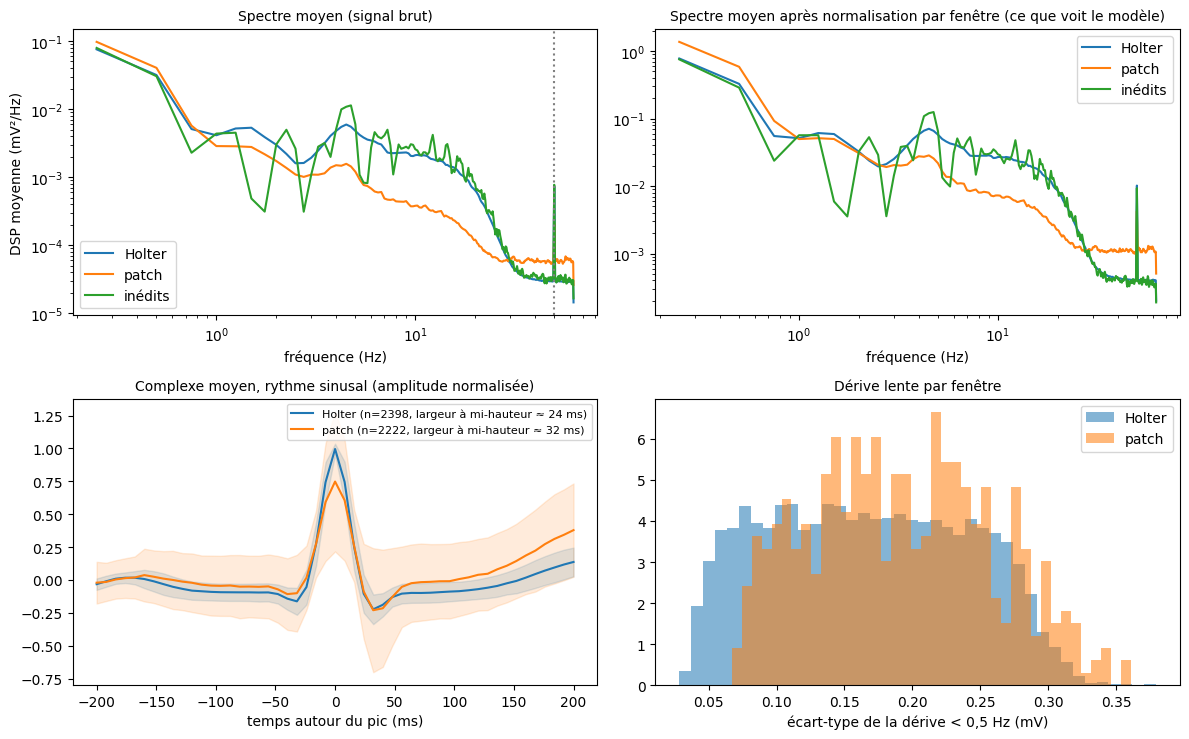

{'Holter': 24.0, 'patch': 32.0} ms (largeur à mi-hauteur du complexe moyen)


In [5]:
def gabarit(X, y, classe=0, n_max=200, demi=25):
    segs = []
    for x in X[y == classe][:n_max].astype("float32"):
        xc = sosfiltfilt(SOS_HP05, x); env = np.abs(sosfiltfilt(SOS_BP, x))
        pics, _ = find_peaks(env, height=0.5 * env.max(), distance=int(0.35 * FS))
        for p in pics:
            if demi <= p < len(x) - demi - 1:
                s = xc[p - demi:p + demi + 1] - xc[p - demi:p - demi + 5].mean(); a = s[np.argmax(np.abs(s))]
                segs.append(s / (abs(a) + 1e-9) * np.sign(a))
    return np.array(segs)
y_Bpool = np.r_[yB["train"], yB["val"]]
G = {"Holter": gabarit(X_A, A["classe_train"]), "patch": gabarit(X_B, y_Bpool)}
t_ms = (np.arange(-25, 26) / FS) * 1000
def largeur_ms(g): m = np.abs(g.mean(0)); return float((m > 0.5 * m.max()).sum() / FS * 1000)

fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
for nom, c in [("Holter", "tab:blue"), ("patch", "tab:orange"), ("inédits", "tab:green")]:
    axs[0, 0].loglog(f_[1:], SPEC[nom][1:], label=nom, color=c)
axs[0, 0].axvline(50, color="gray", ls=":"); axs[0, 0].set_xlabel("fréquence (Hz)"); axs[0, 0].set_ylabel("DSP moyenne (mV²/Hz)"); axs[0, 0].set_title("Spectre moyen (signal brut)", fontsize=10); axs[0, 0].legend()
for nom, X, c in [("Holter", X_A, "tab:blue"), ("patch", X_B, "tab:orange"), ("inédits", X_I, "tab:green")]:
    Z = normaliser_fenetres(X)[..., 0]; ff, Pz = welch(Z, fs=FS, nperseg=500, axis=1); axs[0, 1].loglog(ff[1:], Pz.mean(0)[1:], label=nom, color=c)
axs[0, 1].set_xlabel("fréquence (Hz)"); axs[0, 1].set_title("Spectre moyen après normalisation par fenêtre (ce que voit le modèle)", fontsize=10); axs[0, 1].legend()
for nom, c in [("Holter", "tab:blue"), ("patch", "tab:orange")]:
    g = G[nom]; axs[1, 0].plot(t_ms, g.mean(0), color=c, label=f"{nom} (n={len(g)}, largeur à mi-hauteur ≈ {largeur_ms(g):.0f} ms)"); axs[1, 0].fill_between(t_ms, g.mean(0) - g.std(0), g.mean(0) + g.std(0), color=c, alpha=.15)
axs[1, 0].set_xlabel("temps autour du pic (ms)"); axs[1, 0].set_title("Complexe moyen, rythme sinusal (amplitude normalisée)", fontsize=10); axs[1, 0].legend(fontsize=8)
for nom, X, c in [("Holter", X_A, "tab:blue"), ("patch", X_B, "tab:orange")]:
    axs[1, 1].hist(sosfiltfilt(SOS_LP05, X.astype("float32") - X.astype("float32").mean(1, keepdims=True), axis=1).std(1), bins=40, alpha=.55, density=True, label=nom, color=c)
axs[1, 1].set_xlabel("écart-type de la dérive < 0,5 Hz (mV)"); axs[1, 1].set_title("Dérive lente par fenêtre", fontsize=10); axs[1, 1].legend()
plt.tight_layout(); plt.show()
print({k: round(largeur_ms(v), 1) for k, v in G.items()}, "ms (largeur à mi-hauteur du complexe moyen)")

**Lecture (Q3)** *(chiffres de la table ci-dessus ; mesures sur 18 patients annotés du patch, train + validation)*. Chaque différence est reliée à une stratégie d'adaptation.

| Différence mesurée | Holter → patch | Stratégie associée |
|---|---|---|
| **Amplitude** | crête ×0,58 ; écart-type ×0,86 | z-score par fenêtre (déjà appliqué : l'amplitude seule disparaît) ; **gain** dans l'augmentation, utile seulement par son effet sur le rapport signal/bruit |
| **Rapport signal/bruit** | rapport crête QRS / bruit > 30 Hz : 7,1 contre 21,6 (×0,33) | **bruit** et **gain** dans l'augmentation |
| **Spectre : dérive** | part d'énergie < 0,5 Hz : 53 % contre 29 % (×1,84) ; mais l'écart-type de la dérive n'augmente que de 15 % (0,192 contre 0,167 mV) : la part d'énergie monte surtout parce que le complexe QRS est plus faible (bandes 5–15 et 15–40 Hz à ×0,27 et ×0,40) | **dérive** dans l'augmentation ; filtre passe-haut possible (non testé) |
| **Spectre : bruit large bande** | plancher > 40 Hz ×2,0 ; bruit blanc équivalent 0,060 contre 0,043 mV | **bruit** dans l'augmentation |
| **Raie secteur (50 Hz)** | présente dans les deux appareils et **plus faible** dans le patch (0,0105 contre 0,0198 mV ; elle domine dans 42 % des fenêtres contre 76 %) | le patch n'a pas d'excès de secteur : la transformation « secteur » n'imite pas une différence mesurée, elle ajoute de la variabilité |
| **Morphologie** | complexes bien moins « pointus » (aplatissement 0,14 contre 4,4) ; largeur à mi-hauteur du complexe moyen 32 contre 24 ms (résolution 8 ms : indicatif) | **non simulable par les transformations choisies** : demande des annotations du patch, donc **ajustement fin** |
| **Fréquence cardiaque** | moyennes proches (81 contre 83 bpm) | pas de stratégie nécessaire ; la tête « fc » du multitâche ne se transfère pas telle quelle (partie 6) |

**Fenêtres « inédits »** : leur amplitude, leur spectre et leur rapport signal/bruit sont proches de ceux du Holter ; leur fréquence cardiaque moyenne (100,8 bpm) est plus élevée que celle des jeux annotés (≈ 83 bpm). Elles ne servent à aucun réglage ici.

**Limite** : les paramètres de l'augmentation sont calibrés sur les signaux (sans les classes) des 18 patients du patch utilisés dans les comparaisons ; l'influence est de quatre scalaires, mais elle existe.

### Paramètres de l'augmentation, déduits des mesures (train uniquement)
Chaque transformation imite une différence mesurée. Le **gain** est appliqué *avant* le bruit : après normalisation par fenêtre, un gain seul n'a aucun effet (partie 1), il n'agit qu'en dégradant le rapport signal/bruit. Les amplitudes sont tirées uniformément dans $[0,\ \text{max}]$ ; les maxima sont calibrés pour que l'écart moyen entre appareils soit reproduit.
- **gain** : $g \sim \mathcal U(g_{min}, 1)$ avec $g_{min} = 2r-1$, $r$ = rapport des crêtes patch / Holter ;
- **dérive** : deux sinusoïdes de 0,05 à 0,5 Hz, d'amplitude $\mathcal U(0, a_{max})$, avec $a_{max} = \sqrt3\times$ (excès d'écart-type de dérive du patch sur le Holter) ;
- **bruit** : bruit blanc d'écart-type $\mathcal U(0, s_{max})$, $s_{max} = \sqrt3\times$ (excès de bruit blanc équivalent du patch) ;
- **secteur** : sinusoïde à $50 \pm 0{,}1$ Hz, phase aléatoire, amplitude $\mathcal U(0, 2\times$ amplitude médiane de la raie du patch$)$.

rapport de crête patch/Holter r = 0.58 | excès de dérive 0.095 mV | excès de bruit blanc 0.042 mV
PARAMS_AUG = {'gain': (0.2, 1.0), 'derive_max': 0.164, 'bruit_max': 0.073, 'secteur_max': 0.021}


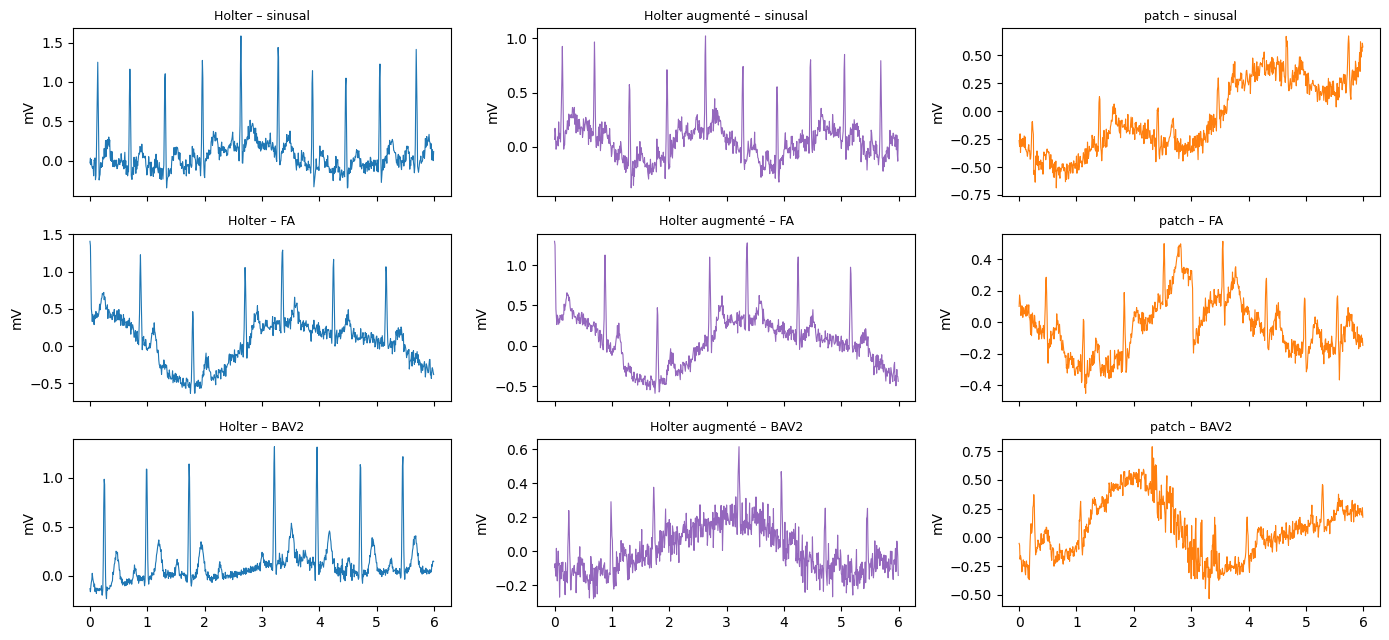

In [6]:
r_amp = CARAC.loc["crête (centile 99,5 de |x|, mV)", "rapport patch / Holter"]
exc_derive = float(np.sqrt(max(0.0, CAR["patch"]["dérive < 0,5 Hz (écart-type, mV)"] ** 2 - CAR["Holter"]["dérive < 0,5 Hz (écart-type, mV)"] ** 2)))
exc_bruit = float(np.sqrt(max(0.0, CAR["patch"]["bruit blanc équivalent (écart-type, mV)"] ** 2 - CAR["Holter"]["bruit blanc équivalent (écart-type, mV)"] ** 2)))
PARAMS_AUG = dict(gain=(float(np.clip(2 * r_amp - 1, 0.2, 1.0)), 1.0), derive_max=float(np.sqrt(3) * exc_derive),
                  bruit_max=float(np.sqrt(3) * exc_bruit), secteur_max=float(2 * CAR["patch"]["raie 50 Hz : amplitude médiane (mV)"]))
print("rapport de crête patch/Holter r = %.2f" % r_amp, "| excès de dérive %.3f mV | excès de bruit blanc %.3f mV" % (exc_derive, exc_bruit))
print("PARAMS_AUG =", {k: (tuple(round(v, 3) for v in val) if isinstance(val, tuple) else round(val, 3)) for k, val in PARAMS_AUG.items()})

T_S = np.arange(1250) / FS
TOUTES = ("gain", "derive", "bruit", "secteur")
def augmenter_patch(X, rng, actives=TOUTES, P=None):
    P = P or PARAMS_AUG; n = len(X); X = X.astype("float32").copy()
    if "gain" in actives:
        X *= rng.uniform(P["gain"][0], P["gain"][1], size=(n, 1)).astype("float32")
    if "derive" in actives:
        for _ in range(2):
            f = rng.uniform(0.05, 0.5, (n, 1)); a = rng.uniform(0, P["derive_max"], (n, 1)); ph = rng.uniform(0, 2 * np.pi, (n, 1))
            X += (a * np.sin(2 * np.pi * f * T_S[None] + ph)).astype("float32")
    if "bruit" in actives:
        X += (rng.standard_normal(X.shape) * rng.uniform(0, P["bruit_max"], (n, 1))).astype("float32")
    if "secteur" in actives:
        a = rng.uniform(0, P["secteur_max"], (n, 1)); f = 50 + rng.normal(0, 0.1, (n, 1)); ph = rng.uniform(0, 2 * np.pi, (n, 1))
        X += (a * np.sin(2 * np.pi * f * T_S[None] + ph)).astype("float32")
    return X

# Contrôle visuel : mêmes fenêtres Holter, avant / après augmentation, et fenêtres patch du même rythme
rng_v = np.random.default_rng(1); idx = [np.where(A["classe_train"] == k)[0][0] for k in (0, 1, 4)]
Xa = augmenter_patch(A["X_train"][idx], rng_v)
fig, axs = plt.subplots(3, 3, figsize=(14, 6.5), sharex=True); t6 = np.arange(6 * FS) / FS
for j, (i, k) in enumerate(zip(idx, (0, 1, 4))):
    ib = np.where(y_Bpool == k)[0][0]
    for c, (sig, titre, col) in enumerate([(A["X_train"][i], "Holter", "tab:blue"), (Xa[j], "Holter augmenté", "tab:purple"), (X_B[ib], "patch", "tab:orange")]):
        axs[j, c].plot(t6, sig[:6 * FS].astype("float32"), lw=.8, color=col); axs[j, c].set_title(f"{titre} – {NOMS[k]}", fontsize=9); axs[j, c].set_ylabel("mV")
plt.tight_layout(); plt.show()

## 3. Modèles, entraînement sur le Holter et fonctions d'adaptation

- **CNN de départ** (`cnn1d`, 51 365 paramètres) tel que fourni. **Modèle multitâche** (`cnn_mt`) : même tronc, une tête « rythme » (softmax) et une tête « fc » (régression, `Dense(1)`), perte $\mathcal L = \text{CE}_{pondérée} + \lambda\,\text{MSE}(\text{fc standardisée})$.
- **Entraînement Holter** : Adam (1e-3), batch 64, au plus 12 époques, poids de classes du Holter (via `sample_weight`, équivalent à `class_weight`), **`EarlyStopping`** sur la perte de validation du rythme (patience 3, poids restaurés). Le même générateur de lots sert à toutes les variantes (avec ou sans augmentation, avec ou sans tête fc), pour que seules les différences voulues les séparent.
- **Adaptation au patch** (`adapter`) : *extraction* (seule la couche `rythme` est entraînée), *ajustement fin partiel* (dernier bloc convolutif + `representation` + sorties), *ajustement fin complet*, ou *entraînement depuis zéro* sur le patch. Poids de classes recalculés sur les patients d'entraînement du pli.

In [ ]:
def cnn_mt():
    e = keras.Input((1250, 1)); x = e
    for filtres in (16, 32, 64, 64):
        x = layers.Conv1D(filtres, 7, padding="same", activation="relu")(x)
        x = layers.MaxPooling1D(2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu", name="representation")(x)
    return keras.Model(e, {"rythme": layers.Dense(5, activation="softmax", name="rythme")(x), "fc": layers.Dense(1, name="fc")(x)}, name="cnn_mt")

class Lot(keras.utils.PyDataset):
    # Lots de fenêtres brutes -> (augmentation éventuelle) -> normalisation par fenêtre -> poids d'échantillon par classe
    def __init__(self, Xraw, y, fc_z, pw, augment=None, batch=64, seed=0, multitache=False):
        super().__init__(); self.X, self.y, self.fc, self.pw, self.augment, self.batch, self.multi = Xraw, y, fc_z, pw, augment, batch, multitache
        self.rng = np.random.default_rng(seed); self.idx = np.arange(len(y)); self.rng.shuffle(self.idx)
    def __len__(self): return int(np.ceil(len(self.y) / self.batch))
    def __getitem__(self, i):
        j = self.idx[i * self.batch:(i + 1) * self.batch]; x = self.X[j]
        if self.augment is not None: x = self.augment(x, self.rng)
        x = normaliser_fenetres(x); w = self.pw[self.y[j]].astype("float32")
        if self.multi: return x, {"rythme": self.y[j], "fc": self.fc[j]}, {"rythme": w, "fc": np.ones_like(w)}
        return x, self.y[j], w
    def on_epoch_end(self): self.rng.shuffle(self.idx)

def proba_rythme(m, S):
    out = m.predict(S, batch_size=256, verbose=0)
    return out["rythme"] if isinstance(out, dict) else out
def fc_predite(m, S):   # fréquence cardiaque prédite, en bpm
    out = m.predict(S, batch_size=256, verbose=0); return out["fc"][:, 0] * FC_SD + FC_MU

H = {}   # (nom, graine) -> (modèle Holter, infos)
def entrainer_holter(nom, graine, lam=None, actives=None, epochs=None):
    epochs = EP_H if epochs is None else epochs; chemin = f"{MODELES}{nom}_s{graine}"
    if (nom, graine) in H: return H[(nom, graine)]
    if os.path.exists(chemin + ".keras") and not RECALCULER:
        H[(nom, graine)] = (keras.models.load_model(chemin + ".keras"), json.load(open(chemin + ".json")))
        return H[(nom, graine)]
    fixer_graine(graine); multi = lam is not None; m = cnn_mt() if multi else cnn1d()
    if multi: m.compile(keras.optimizers.Adam(1e-3), loss={"rythme": "sparse_categorical_crossentropy", "fc": "mse"}, loss_weights={"rythme": 1.0, "fc": float(lam)})
    else:     m.compile(keras.optimizers.Adam(1e-3), "sparse_categorical_crossentropy")
    aug = None if actives is None else (lambda x, rng: augmenter_patch(x, rng, actives))
    lot = Lot(XA_RAW["train"], yA["train"], FCA_Z["train"], poids_arr, aug, 64, graine, multi)
    wv = poids_arr[yA["val"]].astype("float32")
    val = (SA["val"], {"rythme": yA["val"], "fc": FCA_Z["val"]}, {"rythme": wv, "fc": np.ones_like(wv)}) if multi else (SA["val"], yA["val"], wv)
    cb = [keras.callbacks.EarlyStopping(monitor="val_rythme_loss" if multi else "val_loss", mode="min", patience=3, restore_best_weights=True)] if USE_ES else []
    t0 = time.time(); h = m.fit(lot, epochs=epochs, validation_data=val, callbacks=cb, verbose=0)
    cle = "val_rythme_loss" if multi else "val_loss"
    info = dict(hist={k: [float(v) for v in vs] for k, vs in h.history.items()}, duree=time.time() - t0, epoques=len(h.history["loss"]), meilleure=int(np.argmin(h.history[cle])) + 1)
    m.save(chemin + ".keras"); json.dump(info, open(chemin + ".json", "w")); H[(nom, graine)] = (m, info)
    return H[(nom, graine)]

def adapter(base, mode, Xtr, ytr, fctr, seed, epochs, lr, lam=0.0, batch=32):
    # Xtr : fenêtres déjà normalisées ; base : modèle Holter (ou modèle neuf si mode == "scratch")
    fixer_graine(seed)
    if mode == "scratch": m = base
    else: m = keras.models.clone_model(base); m.set_weights(base.get_weights())
    conv = [l.name for l in m.layers if isinstance(l, layers.Conv1D)]
    gele = {"extraction": lambda n: n != "rythme", "ft_partiel": lambda n: n not in (conv[-1], "representation", "rythme", "fc"),
            "ft_complet": lambda n: False, "scratch": lambda n: False}[mode]
    for l in m.layers: l.trainable = not gele(l.name)
    multi = isinstance(m.output, dict)
    if multi: m.compile(keras.optimizers.Adam(lr), loss={"rythme": "sparse_categorical_crossentropy", "fc": "mse"}, loss_weights={"rythme": 1.0, "fc": float(lam)})
    else:     m.compile(keras.optimizers.Adam(lr), "sparse_categorical_crossentropy")
    wk = len(ytr) / (5 * np.maximum(np.bincount(ytr, minlength=5), 1)); w = wk[ytr].astype("float32")
    if multi: m.fit(Xtr, {"rythme": ytr, "fc": fctr}, sample_weight={"rythme": w, "fc": np.ones_like(w)}, epochs=epochs, batch_size=batch, shuffle=True, verbose=0)
    else:     m.fit(Xtr, ytr, sample_weight=w, epochs=epochs, batch_size=batch, shuffle=True, verbose=0)
    return m

def f1m(y, p, present=False):
    pr = p.argmax(1); labs = sorted(set(np.asarray(y).tolist()) | set(pr.tolist())) if present else list(range(5))
    return float(f1_score(y, pr, average="macro", labels=labs, zero_division=0))

ADAPT = {}
import pickle
CACHE_RES = MODELES + "cache_resultats.pkl"
CACHE = pickle.load(open(CACHE_RES, "rb")) if os.path.exists(CACHE_RES) and not RECALCULER else {}
def evaluer_cv(nom, fabrique, graines=None):
    graines = SEEDS_H if graines is None else graines; yT = yB["train"]
    cle = nom + "|" + repr(sorted(ADAPT.items())) + "|" + repr(tuple(graines))   # résultats mémorisés sur disque (reprise après interruption)
    if cle in CACHE: return CACHE[cle]
    res = dict(nom=nom, f1s=[], plis=[], oof=[]); t0 = time.time()
    for s in graines:
        oof = np.zeros((len(yT), 5), "float32"); pl = []
        for tr, te in PLIS:
            m = fabrique(SB["train"][tr], yT[tr], FCB_Z["train"][tr], s); oof[te] = proba_rythme(m, SB["train"][te]); pl.append(f1m(yT[te], oof[te], True)); del m
        res["f1s"].append(f1m(yT, oof)); res["plis"].append(pl); res["oof"].append(oof); gc.collect()
    res["f1"], res["std"] = float(np.mean(res["f1s"])), float(np.std(res["f1s"]))
    res["rappels"] = np.mean([recall_score(yT, o.argmax(1), average=None, labels=range(5), zero_division=0) for o in res["oof"]], 0)
    res["std_plis"] = float(np.mean([np.std(p) for p in res["plis"]])); res["duree"] = time.time() - t0
    CACHE[cle] = res; pickle.dump(CACHE, open(CACHE_RES, "wb"))
    return res

def fabrique(mode, holter=None, lam_ft=0.0):
    def f(Xtr, ytr, fctr, seed):
        if mode == "zs": return H[(holter, seed)][0]
        if mode == "scratch":
            fixer_graine(seed); return adapter(cnn_mt() if lam_ft > 0 else cnn1d(), "scratch", Xtr, ytr, fctr, seed, *ADAPT["scratch"], lam=lam_ft)
        return adapter(H[(holter, seed)][0], mode, Xtr, ytr, fctr, seed, *ADAPT[mode], lam=lam_ft)
    return f

### 3.1 Entraînement du CNN de départ sur le Holter (références, 2 graines)

Temps (entraînements Holter de référence) : 0 s


,graine,epoques_retenues,epoques_faites,duree_s,F1_Holter_val,F1_patch_val
0,0,9,12,120,0.9741,0.7251
1,1,12,12,124,0.9876,0.6944


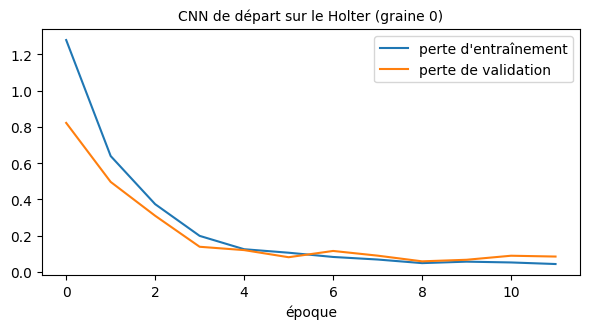

In [8]:
t0 = time.time()
for s in SEEDS_H: entrainer_holter("base", s)
print("Temps (entraînements Holter de référence) : %.0f s" % (time.time() - t0))
lignes = []
for s in SEEDS_H:
    m, info = H[("base", s)]; r_ = evaluer_rythme(yA["val"], proba_rythme(m, SA["val"])); rp = evaluer_rythme(yB["val"], proba_rythme(m, SB["val"]))
    lignes.append(dict(graine=s, epoques_retenues=info["meilleure"], epoques_faites=info["epoques"], duree_s=round(info["duree"]), F1_Holter_val=r_["f1_macro"], F1_patch_val=rp["f1_macro"]))
    journaliser(3, "Holter", f"cnn1d de départ (graine {s})", r_["f1_macro"], f"F1 patch val {rp['f1_macro']} ; époques {info['meilleure']}")
display(pd.DataFrame(lignes))
fig, ax = plt.subplots(figsize=(6, 3.4)); info = H[("base", SEEDS_H[0])][1]["hist"]
ax.plot(info["loss"], label="perte d'entraînement"); ax.plot(info["val_loss"], label="perte de validation"); ax.set_xlabel("époque"); ax.set_title("CNN de départ sur le Holter (graine %d)" % SEEDS_H[0], fontsize=10); ax.legend(); plt.tight_layout(); plt.show()

## 4. Question 1 – Holter tel quel, patch seul, extraction, ajustement fin (validation croisée par patient)

Toutes les lignes sont évaluées sur les **mêmes 12 patients du patch**, patient par patient hors pli (4 plis). Le F1 macro est calculé sur les 300 prédictions hors pli, pour chaque graine ; on donne la moyenne et l'écart-type entre graines.

**Réglage des hyperparamètres d'adaptation** (taux d'apprentissage et nombre d'époques) : petite grille, **une graine (0)**, évaluée avec la même validation croisée par patient ; les essais non retenus restent dans le journal.

In [9]:
GRILLES = {"extraction": [(1e-3, 40), (1e-2, 40)], "ft_complet": [(1e-3, 20), (3e-4, 20), (1e-4, 20)],
           "ft_partiel": [(1e-3, 20), (3e-4, 20)], "scratch": [(1e-3, 30), (1e-3, 60)]}
if RAPIDE: GRILLES = {k: v[:1] for k, v in GRILLES.items()}; 
ADAPT = {}; lignes = []
for mode, grille in GRILLES.items():
    meilleur = None
    for lr, ep in grille:
        ADAPT[mode] = (ep, lr)
        r = evaluer_cv(f"grille {mode}", fabrique(mode, "base"), graines=(SEEDS_H[0],))
        lignes.append(dict(mode=mode, lr=lr, epoques=ep, F1_CV=round(r["f1"], 3), duree_s=round(r["duree"])))
        journaliser(3, "grille", f"{mode} lr={lr} ep={ep} (graine {SEEDS_H[0]})", r["f1"], "réglage CV, une graine")
        if meilleur is None or r["f1"] > meilleur[0]: meilleur = (r["f1"], ep, lr)
    ADAPT[mode] = (meilleur[1], meilleur[2])
display(pd.DataFrame(lignes)); print("Hyperparamètres retenus (époques, lr) :", ADAPT)

,mode,lr,epoques,F1_CV,duree_s
0,extraction,0.0010,40,0.762,27
1,extraction,0.0100,40,0.793,27
2,ft_complet,0.0010,20,0.854,32
3,ft_complet,0.0003,20,0.842,32
4,ft_complet,0.0001,20,0.828,32
5,ft_partiel,0.0010,20,0.828,18
6,ft_partiel,0.0003,20,0.816,19
7,scratch,0.0010,30,0.392,44
8,scratch,0.0010,60,0.498,79


Hyperparamètres retenus (époques, lr) : {'extraction': (40, 0.01), 'ft_complet': (20, 0.001), 'ft_partiel': (20, 0.001), 'scratch': (60, 0.001)}


,F1_macro_CV,écart_type_graines,écart_type_plis,R_sinusal,R_FA,R_ESV,R_tachy.,R_BAV2,durée_s
stratégie,,,,,,,,,
Holter tel quel,0.584,0.018,0.165,0.42,0.47,1.00,0.40,0.97,2
Patch seul (depuis zéro),0.485,0.014,0.118,0.49,0.44,0.76,0.66,0.07,164
Extraction de caractéristiques,0.784,0.008,0.132,0.70,0.80,0.84,0.86,0.85,54
Ajustement fin partiel,0.827,0.001,0.118,0.84,0.86,0.87,0.86,0.73,36
Ajustement fin complet,0.867,0.013,0.124,0.87,0.91,0.90,0.86,0.77,64


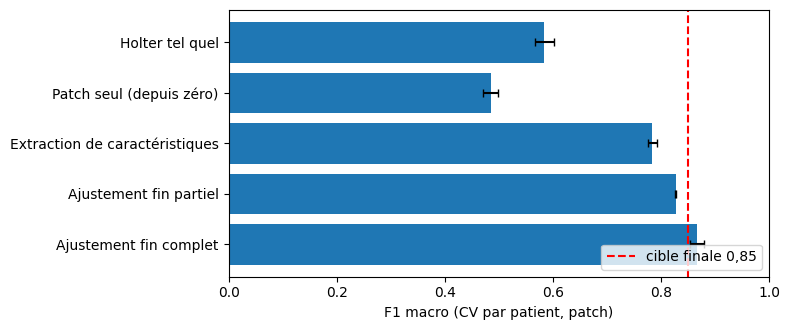

In [10]:
RES = {}
RES["Holter tel quel"] = evaluer_cv("Holter tel quel", fabrique("zs", "base"))
RES["Patch seul (depuis zéro)"] = evaluer_cv("Patch seul (depuis zéro)", fabrique("scratch"))
RES["Extraction de caractéristiques"] = evaluer_cv("Extraction de caractéristiques", fabrique("extraction", "base"))
RES["Ajustement fin partiel"] = evaluer_cv("Ajustement fin partiel", fabrique("ft_partiel", "base"))
RES["Ajustement fin complet"] = evaluer_cv("Ajustement fin complet", fabrique("ft_complet", "base"))
def tableau(noms):
    return pd.DataFrame([dict(stratégie=n, F1_macro_CV=round(RES[n]["f1"], 3), écart_type_graines=round(RES[n]["std"], 3), écart_type_plis=round(RES[n]["std_plis"], 3),
                              **{"R_" + c: round(float(v), 2) for c, v in zip(NOMS, RES[n]["rappels"])}, durée_s=round(RES[n]["duree"])) for n in noms]).set_index("stratégie")
for n in ["Holter tel quel", "Patch seul (depuis zéro)", "Extraction de caractéristiques", "Ajustement fin partiel", "Ajustement fin complet"]:
    journaliser(3, "Q1", n, RES[n]["f1"], f"CV 4 plis par patient, écart-type graines {RES[n]['std']:.3f}")
display(tableau(list(RES)))
fig, ax = plt.subplots(figsize=(8, 3.4)); nn = list(RES)
ax.barh(nn, [RES[n]["f1"] for n in nn], xerr=[RES[n]["std"] for n in nn], color="tab:blue", capsize=3); ax.axvline(0.85, color="red", ls="--", label="cible finale 0,85")
ax.set_xlim(0, 1); ax.set_xlabel("F1 macro (CV par patient, patch)"); ax.legend(loc="lower right"); ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Lecture (Q1)** *(chiffres de l'exécution ; CV par patient, 12 patients, 2 graines)*.
- **CNN du Holter tel quel : F1 0,584 ± 0,018**, alors qu'il atteint 0,98 sur la validation du Holter : l'écart vient du **décalage de domaine**. Ses rappels (sinusal 0,42, tachycardie 0,40 contre BAV2 0,97 et ESV 1,00) indiquent que beaucoup de fenêtres du patch sont envoyées vers BAV2 et ESV (on ne voit ici que les rappels, pas les précisions).
- **CNN entraîné sur le patch seul : 0,485 ± 0,014**, pire que le Holter tel quel : 9 patients d'entraînement par pli ne suffisent pas (rappel BAV2 0,07). Le nombre d'époques retenu (60) est à la borne haute de la grille : un entraînement plus long n'a pas été essayé.
- **Extraction de caractéristiques : 0,784 ± 0,008** en n'entraînant que 325 paramètres ; **ajustement fin partiel : 0,827 ± 0,001** ; **ajustement fin complet : 0,867 ± 0,013**. Plus on adapte de paramètres, mieux c'est ici ; seul le rappel BAV2 fait exception (0,85 en extraction contre 0,77 en ajustement fin complet), sur 3 patients seulement.
- **Incertitudes** : l'écart-type entre plis (0,09 à 0,17, 3 patients par pli) est bien plus grand que l'écart-type entre graines (0,001 à 0,018, 2 graines) : c'est la variabilité entre patients qui domine, et l'écart-type entre graines la sous-estime. Les hyperparamètres d'adaptation ont été choisis sur cette même CV (une graine) : les F1 de cette partie sont **légèrement optimistes**.

## 5. Question 2 – Augmentation de données imitant le patch (pendant l'entraînement sur le Holter)

Le CNN est entraîné sur le Holter **augmenté** (gain, dérive, bruit, secteur : paramètres de la partie 2, nouveaux tirages à chaque époque), avec exactement le même protocole que la référence. On compare : (a) Holter augmenté tel quel, (b) ajustement fin seul (Q1), (c) augmentation **puis** ajustement fin (combinaison). Une ablation (une graine, chaque transformation seule) indique laquelle compte, sur les **18 patients annotés du patch** (train + validation ; aucun n'a servi à entraîner ces modèles).

In [11]:
t0 = time.time()
for s in SEEDS_H: entrainer_holter("aug", s, actives=TOUTES)
RES["Holter augmenté, tel quel"] = evaluer_cv("Holter augmenté, tel quel", fabrique("zs", "aug"))
RES["Holter augmenté + ajustement fin"] = evaluer_cv("Holter augmenté + ajustement fin", fabrique("ft_complet", "aug"))
for n in ["Holter augmenté, tel quel", "Holter augmenté + ajustement fin"]: journaliser(3, "Q2", n, RES[n]["f1"], f"CV par patient, écart-type graines {RES[n]['std']:.3f}")
print("Temps Q2 (hors ablation) : %.0f s" % (time.time() - t0))
S18 = np.concatenate([SB["train"], SB["val"]]); y18 = np.r_[yB["train"], yB["val"]]; FC18_Z = np.r_[FCB_Z["train"], FCB_Z["val"]]; PAT18 = np.r_[B["patient_train"], B["patient_val"]]
hol = {n: np.mean([evaluer_rythme(yA["val"], proba_rythme(H[(n, s)][0], SA["val"]))["f1_macro"] for s in SEEDS_H]) for n in ["base", "aug"]}
display(pd.DataFrame([dict(modèle=n, F1_Holter_val=round(hol[k], 3), époques_retenues=np.mean([H[(k, s)][1]["meilleure"] for s in SEEDS_H])) for n, k in [("Holter de référence", "base"), ("Holter augmenté", "aug")]]).set_index("modèle"))
display(tableau(["Holter tel quel", "Holter augmenté, tel quel", "Ajustement fin complet", "Holter augmenté + ajustement fin"]))

Temps Q2 (hors ablation) : 64 s


,F1_Holter_val,époques_retenues
modèle,,
Holter de référence,0.981,10.5
Holter augmenté,0.983,12.0


,F1_macro_CV,écart_type_graines,écart_type_plis,R_sinusal,R_FA,R_ESV,R_tachy.,R_BAV2,durée_s
stratégie,,,,,,,,,
Holter tel quel,0.584,0.018,0.165,0.42,0.47,1.00,0.40,0.97,2
"Holter augmenté, tel quel",0.828,0.003,0.146,0.71,0.91,0.99,0.72,0.92,3
Ajustement fin complet,0.867,0.013,0.124,0.87,0.91,0.90,0.86,0.77,64
Holter augmenté + ajustement fin,0.877,0.009,0.087,0.89,0.93,0.98,0.86,0.69,64


In [12]:
# Ablation : chaque transformation seule (graine 0), évaluée sans adaptation sur les 18 patients annotés du patch
s0 = SEEDS_H[0]; abl = [("aucune (référence)", "base", None), ("gain seul", "aug_gain", ("gain",)), ("dérive seule", "aug_derive", ("derive",)),
                        ("bruit seul", "aug_bruit", ("bruit",)), ("secteur seul", "aug_secteur", ("secteur",)), ("toutes", "aug", TOUTES)]
lignes = []
for lib, nom, act in abl:
    if act is not None and nom != "aug": entrainer_holter(nom, s0, actives=act)
    m = H[(nom, s0)][0]
    f_p = f1m(y18, proba_rythme(m, S18)); f_h = evaluer_rythme(yA["val"], proba_rythme(m, SA["val"]))["f1_macro"]
    lignes.append(dict(augmentation=lib, F1_patch_18_patients=round(f_p, 3), F1_Holter_val=f_h)); journaliser(3, "Q2-ablation", lib, f_p, f"Holter tel quel, F1 Holter val {f_h}")
T_ABL = pd.DataFrame(lignes).set_index("augmentation"); display(T_ABL)

,F1_patch_18_patients,F1_Holter_val
augmentation,,
aucune (référence),0.620,0.9741
gain seul,0.534,0.9821
dérive seule,0.700,0.9829
bruit seul,0.617,0.9863
secteur seul,0.642,0.9689
toutes,0.868,0.9852


**Lecture (Q2)** *(chiffres de l'exécution)*.
- **L'augmentation seule, sans aucune annotation du patch, fait passer le F1 CV de 0,584 à 0,828 ± 0,003 (+0,244)** : elle comble environ 85 % de l'écart entre le Holter tel quel et l'ajustement fin complet (0,867). Le F1 du Holter n'en souffre pas (validation 0,983 contre 0,981).
- **Combinaison augmentation + ajustement fin : 0,877 ± 0,009** contre 0,867 ± 0,013 pour l'ajustement fin seul : +0,010, **dans l'incertitude**. Les rappels sinusal et ESV progressent un peu (0,89 et 0,98), celui du BAV2 baisse (0,69 contre 0,77).
- **Ablation (une seule graine, Holter tel quel, 18 patients du patch)** : aucune 0,620 ; gain seul 0,534 ; dérive seule 0,700 ; bruit seul 0,617 ; secteur seul 0,642 ; **toutes 0,868**. Le gain seul ne devrait avoir **aucun effet** après normalisation (partie 1) : son écart de −0,086 mesure donc la **variabilité d'un entraînement à l'autre**. Conséquence : aucune différence inférieure à environ 0,1 n'est interprétable dans cette ablation. Seul l'effet de « toutes » (+0,25) dépasse ce bruit ; les effets individuels de la dérive ou du bruit ne sont pas démontrés.
- **Réponse** : l'augmentation est très efficace quand il n'y a pas d'annotation du patch (+0,24), et elle ne coûte rien ; une fois que l'on dispose de 12 patients annotés, son apport au-dessus de l'ajustement fin n'est pas démontré.

## 6. Question 4 – Modèle multitâche : rythme + fréquence cardiaque

Perte $\mathcal L = \text{CE}_{pondérée}(\text{rythme}) + \lambda\,\text{MSE}(\text{fc standardisée})$. La fréquence cardiaque est annotée pour **tous** les patients (Holter et patch) : la tête auxiliaire peut aussi être entraînée lors de l'ajustement fin. On étudie $\lambda \in \{0\ (\text{référence}), 0{,}1, 0{,}5, 2\}$ ; $\lambda=0$ est le CNN de départ. L'arrêt précoce surveille la perte **du rythme seul**, pour que son critère ne dépende pas de $\lambda$.

In [13]:
LAMBDAS = (0.5,) if RAPIDE else (0.1, 0.5, 2.0)
t0 = time.time()
for lam in LAMBDAS:
    for s in SEEDS_H: entrainer_holter(f"mt{lam}", s, lam=lam)
    RES[f"Multitâche λ={lam}, tel quel"] = evaluer_cv(f"Multitâche λ={lam}, tel quel", fabrique("zs", f"mt{lam}"))
    RES[f"Multitâche λ={lam} + ajustement fin"] = evaluer_cv(f"Multitâche λ={lam} + ajustement fin", fabrique("ft_complet", f"mt{lam}", lam_ft=lam))
    for n in (f"Multitâche λ={lam}, tel quel", f"Multitâche λ={lam} + ajustement fin"): journaliser(3, "Q4", n, RES[n]["f1"], f"CV par patient, écart-type graines {RES[n]['std']:.3f}")
print("Temps Q4 : %.0f s" % (time.time() - t0))
lignes = [dict(lam=0.0, F1_Holter_val=round(hol["base"], 3), MAE_fc_Holter_bpm=np.nan, MAE_fc_patch_bpm=np.nan, F1_patch_18_tel_quel=round(np.mean([f1m(y18, proba_rythme(H[("base", s)][0], S18)) for s in SEEDS_H]), 3),
               F1_CV_tel_quel=round(RES["Holter tel quel"]["f1"], 3), F1_CV_ajust_fin=round(RES["Ajustement fin complet"]["f1"], 3), ecart_type=round(RES["Ajustement fin complet"]["std"], 3))]
for lam in LAMBDAS:
    mm = [H[(f"mt{lam}", s)][0] for s in SEEDS_H]
    lignes.append(dict(lam=lam, F1_Holter_val=round(np.mean([evaluer_rythme(yA["val"], proba_rythme(m, SA["val"]))["f1_macro"] for m in mm]), 3),
        MAE_fc_Holter_bpm=round(np.mean([np.abs(fc_predite(m, SA["val"]) - A["fc_val"]).mean() for m in mm]), 2),
        MAE_fc_patch_bpm=round(np.mean([np.abs(fc_predite(m, S18) - np.r_[B["fc_train"], B["fc_val"]]).mean() for m in mm]), 2),
        F1_patch_18_tel_quel=round(np.mean([f1m(y18, proba_rythme(m, S18)) for m in mm]), 3),
        F1_CV_tel_quel=round(RES[f"Multitâche λ={lam}, tel quel"]["f1"], 3), F1_CV_ajust_fin=round(RES[f"Multitâche λ={lam} + ajustement fin"]["f1"], 3), ecart_type=round(RES[f"Multitâche λ={lam} + ajustement fin"]["std"], 3)))
T_LAM = pd.DataFrame(lignes).set_index("lam"); display(T_LAM)
LAM_STAR = max(LAMBDAS, key=lambda l: RES[f"Multitâche λ={l} + ajustement fin"]["f1"]); print("λ retenu parmi les valeurs > 0 (meilleur F1 CV après ajustement fin) :", LAM_STAR)

Temps Q4 : 209 s


,F1_Holter_val,MAE_fc_Holter_bpm,MAE_fc_patch_bpm,F1_patch_18_tel_quel,F1_CV_tel_quel,F1_CV_ajust_fin,ecart_type
lam,,,,,,,
0.0,0.981,NaN,NaN,0.631,0.584,0.867,0.013
0.1,0.986,3.76,10.48,0.635,0.577,0.877,0.015
0.5,0.989,2.49,9.81,0.701,0.652,0.896,0.019
2.0,0.972,2.28,9.90,0.544,0.492,0.869,0.017


λ retenu parmi les valeurs > 0 (meilleur F1 CV après ajustement fin) : 0.5


In [14]:
# Tâche auxiliaire dans les autres montages : patch seul multitâche, et augmentation + multitâche
t0 = time.time()
RES["Patch seul multitâche (λ*)"] = evaluer_cv("Patch seul multitâche (λ*)", fabrique("scratch", lam_ft=LAM_STAR))
for s in SEEDS_H: entrainer_holter("augmt", s, lam=LAM_STAR, actives=TOUTES)
RES["Aug + multitâche, tel quel"] = evaluer_cv("Aug + multitâche, tel quel", fabrique("zs", "augmt"))
RES["Aug + multitâche + ajustement fin"] = evaluer_cv("Aug + multitâche + ajustement fin", fabrique("ft_complet", "augmt", lam_ft=LAM_STAR))
for n in ["Patch seul multitâche (λ*)", "Aug + multitâche, tel quel", "Aug + multitâche + ajustement fin"]: journaliser(3, "Q4", n, RES[n]["f1"], f"λ*={LAM_STAR}, CV par patient")
print("Temps : %.0f s" % (time.time() - t0))
display(tableau(["Patch seul (depuis zéro)", "Patch seul multitâche (λ*)", "Ajustement fin complet", f"Multitâche λ={LAM_STAR} + ajustement fin", "Holter augmenté + ajustement fin", "Aug + multitâche + ajustement fin"]))

Temps : 237 s


,F1_macro_CV,écart_type_graines,écart_type_plis,R_sinusal,R_FA,R_ESV,R_tachy.,R_BAV2,durée_s
stratégie,,,,,,,,,
Patch seul (depuis zéro),0.485,0.014,0.118,0.49,0.44,0.76,0.66,0.07,164
Patch seul multitâche (λ*),0.561,0.061,0.114,0.47,0.59,0.86,0.81,0.15,165
Ajustement fin complet,0.867,0.013,0.124,0.87,0.91,0.90,0.86,0.77,64
Multitâche λ=0.5 + ajustement fin,0.896,0.019,0.113,0.91,0.94,0.96,0.90,0.74,68
Holter augmenté + ajustement fin,0.877,0.009,0.087,0.89,0.93,0.98,0.86,0.69,64
Aug + multitâche + ajustement fin,0.893,0.021,0.130,0.90,0.93,0.95,0.88,0.80,69


**Lecture (Q4)** *(chiffres de l'exécution ; 2 graines)*.
- **Pour le Holter**, la tâche auxiliaire est apprise : erreur de fréquence cardiaque de 3,8 bpm (λ = 0,1) à 2,3 bpm (λ = 2) sur la validation. Le F1 rythme du Holter reste à 0,97–0,99 (0,981 pour λ = 0, 0,989 pour λ = 0,5, 0,972 pour λ = 2).
- **Sur le patch, la tête « fc » ne se transfère pas** : son erreur est d'environ 10 bpm pour tous les λ, soit environ 3 à 4 fois plus que sur le Holter, avant toute adaptation.
- **Effet sur les rythmes après ajustement fin (CV)** : λ = 0 : 0,867 ; λ = 0,1 : 0,877 ; **λ = 0,5 : 0,896** ; λ = 2 : 0,869. Le meilleur gain (+0,029) vaut environ 1,5 écart-type entre graines (0,013 à 0,019) et la courbe n'est pas monotone (λ = 2 n'apporte rien) : avec 2 graines, l'amélioration est **suggérée, pas démontrée**. Sans adaptation, λ = 0,5 donne 0,652 contre 0,584, et λ = 2 dégrade (0,492).
- **Patch seul** : le multitâche donne 0,561 ± 0,061 contre 0,485 ± 0,014 (+0,076, mais avec une incertitude presque égale à l'écart). **Augmentation + multitâche + ajustement fin** : 0,893 ± 0,021, comme le multitâche seul (0,896) : les deux apports ne s'additionnent pas.
- **Conclusion** : un λ intermédiaire (0,5) semble aider légèrement, surtout le rappel de la FA (0,94 contre 0,91) et de l'ESV (0,96 contre 0,90) ; un λ trop fort nuit. Ce λ a été choisi sur la même CV : l'écart est probablement un peu surestimé.

## 7. Choix de la stratégie, test (une seule fois) et nombre de patients à annoter

**Règle de choix** (fixée avant les chiffres) : (1) parmi les stratégies évaluées en validation croisée, on retient la **liste restreinte** de celles dont le F1 macro moyen est à moins d'un écart-type (minimum 0,01) du meilleur ; (2) on **confirme sur la validation** (6 patients du patch, jamais utilisés jusqu'ici) en entraînant chaque candidat sur les 12 patients d'entraînement ; (3) on retient le meilleur F1 de validation ; en cas d'égalité (écart < 0,01), la stratégie la plus simple.

In [15]:
SPECS = {"Holter tel quel": ("zs", "base", 0.0), "Patch seul (depuis zéro)": ("scratch", None, 0.0), "Extraction de caractéristiques": ("extraction", "base", 0.0),
         "Ajustement fin partiel": ("ft_partiel", "base", 0.0), "Ajustement fin complet": ("ft_complet", "base", 0.0),
         "Holter augmenté, tel quel": ("zs", "aug", 0.0), "Holter augmenté + ajustement fin": ("ft_complet", "aug", 0.0),
         "Patch seul multitâche (λ*)": ("scratch", None, LAM_STAR), "Aug + multitâche, tel quel": ("zs", "augmt", 0.0),
         "Aug + multitâche + ajustement fin": ("ft_complet", "augmt", LAM_STAR)}
for lam in LAMBDAS:
    SPECS[f"Multitâche λ={lam}, tel quel"] = ("zs", f"mt{lam}", 0.0); SPECS[f"Multitâche λ={lam} + ajustement fin"] = ("ft_complet", f"mt{lam}", lam)
SIMPLICITE = ["zs", "extraction", "ft_partiel", "ft_complet", "scratch"]
meilleur = max(RES, key=lambda n: RES[n]["f1"]); marge = max(RES[meilleur]["std"], 0.01)
LISTE = [n for n in RES if RES[n]["f1"] >= RES[meilleur]["f1"] - marge]
print(f"Meilleur F1 en CV : {meilleur} ({RES[meilleur]['f1']:.3f}) ; marge = {marge:.3f} ; liste restreinte : {LISTE}")

def evaluer_val(nom):
    mode, holter, lam = SPECS[nom]; f1s = []; pr = []
    for s in SEEDS_H:
        m = fabrique(mode, holter, lam)(SB["train"], yB["train"], FCB_Z["train"], s); p = proba_rythme(m, SB["val"]); f1s.append(f1m(yB["val"], p)); pr.append(p); del m
    return float(np.mean(f1s)), float(np.std(f1s)), np.mean(pr, 0)
VAL = {n: evaluer_val(n) for n in LISTE}
T_VAL = pd.DataFrame([dict(stratégie=n, F1_CV=round(RES[n]["f1"], 3), F1_validation_6_patients=round(VAL[n][0], 3), écart_type_graines=round(VAL[n][1], 3)) for n in LISTE]).set_index("stratégie"); display(T_VAL)
for n in LISTE: journaliser(3, "choix", n, VAL[n][0], f"F1 validation (6 patients), liste restreinte ; F1 CV {RES[n]['f1']:.3f}")
mv = max(VAL[n][0] for n in LISTE); proches = [n for n in LISTE if VAL[n][0] >= mv - 0.01]
RETENU = min(proches, key=lambda n: SIMPLICITE.index(SPECS[n][0])); MODE, HOLTER, LAM_FT = SPECS[RETENU]
print("Stratégie retenue :", RETENU, "|", SPECS[RETENU])

Meilleur F1 en CV : Multitâche λ=0.5 + ajustement fin (0.896) ; marge = 0.019 ; liste restreinte : ['Multitâche λ=0.5 + ajustement fin', 'Aug + multitâche + ajustement fin']


,F1_CV,F1_validation_6_patients,écart_type_graines
stratégie,,,
Multitâche λ=0.5 + ajustement fin,0.896,0.927,0.008
Aug + multitâche + ajustement fin,0.893,0.909,0.003


Stratégie retenue : Multitâche λ=0.5 + ajustement fin | ('ft_complet', 'mt0.5', 0.5)


In [16]:
# Effectifs par patient (patch, entraînement) : utile pour choisir qui faire annoter
display(pd.crosstab(B["patient_train"], pd.Series(yB["train"]).map(dict(enumerate(NOMS))).values).reindex(columns=NOMS))
display(pd.DataFrame({"patients (train)": [len(set(B["patient_train"][yB["train"] == k])) for k in range(5)], "patients (val)": [len(set(B["patient_val"][yB["val"] == k])) for k in range(5)]}, index=NOMS).T)

col_0,sinusal,FA,ESV,tachy.,BAV2
row_0,,,,,
1000,6,16,0,3,0
1001,6,0,0,0,19
1002,15,0,10,0,0
1003,14,0,11,0,0
1004,6,15,0,4,0
1005,11,0,0,0,14
1006,7,0,18,0,0
1007,21,0,0,4,0
1008,16,0,0,9,0


,sinusal,FA,ESV,tachy.,BAV2
patients (train),12,5,4,7,3
patients (val),6,2,4,3,3


Temps courbe : 250 s


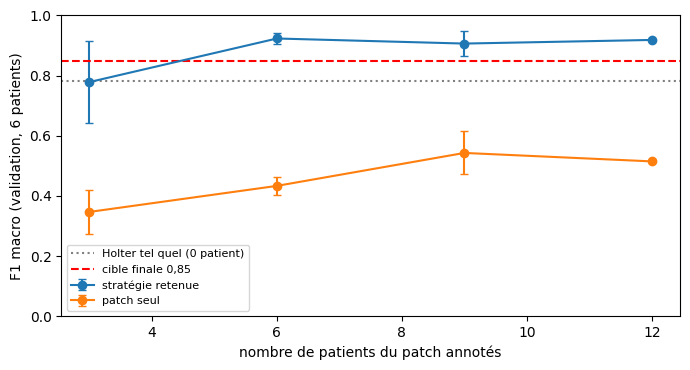

,stratégie,n_patients,mean,std
0,patch seul,3,0.347,0.074
1,patch seul,6,0.433,0.029
2,patch seul,9,0.543,0.072
3,patch seul,12,0.515,NaN
4,stratégie retenue,3,0.779,0.136
5,stratégie retenue,6,0.924,0.019
6,stratégie retenue,9,0.907,0.040
7,stratégie retenue,12,0.919,NaN


In [17]:
# Courbe d'apprentissage : F1 sur les 6 patients de validation en fonction du nombre de patients annotés (sous-ensembles tirés dans les 12 patients d'entraînement)
NS = (3, 12) if RAPIDE else (3, 6, 9, 12); TIRAGES = 1 if RAPIDE else 3
pats = np.unique(B["patient_train"]); courbe = []; t0 = time.time()
for n in NS:
    for d in range(TIRAGES if n < 12 else 1):
        choix = np.random.default_rng(100 + d).choice(pats, n, replace=False); idx = np.where(np.isin(B["patient_train"], choix))[0]
        for nom_c, spec in [("stratégie retenue", (MODE, HOLTER, LAM_FT)), ("patch seul", ("scratch", None, 0.0))]:
            m = fabrique(*spec)(SB["train"][idx], yB["train"][idx], FCB_Z["train"][idx], SEEDS_H[d % len(SEEDS_H)]); courbe.append(dict(n_patients=n, tirage=d, stratégie=nom_c, F1_val=f1m(yB["val"], proba_rythme(m, SB["val"])))); del m
CB = pd.DataFrame(courbe); G_ = CB.groupby(["stratégie", "n_patients"])["F1_val"].agg(["mean", "std"]).reset_index(); print("Temps courbe : %.0f s" % (time.time() - t0))
zs_val = float(np.mean([f1m(yB["val"], proba_rythme(H[(HOLTER or "base", s)][0], SB["val"])) for s in SEEDS_H]))
fig, ax = plt.subplots(figsize=(7, 3.8))
for nom_c, c in [("stratégie retenue", "tab:blue"), ("patch seul", "tab:orange")]:
    g = G_[G_["stratégie"] == nom_c]; ax.errorbar(g["n_patients"], g["mean"], yerr=g["std"].fillna(0), marker="o", capsize=3, label=nom_c, color=c)
ax.axhline(zs_val, color="gray", ls=":", label="Holter tel quel (0 patient)"); ax.axhline(0.85, color="red", ls="--", label="cible finale 0,85")
ax.set_xlabel("nombre de patients du patch annotés"); ax.set_ylabel("F1 macro (validation, 6 patients)"); ax.set_ylim(0, 1); ax.legend(fontsize=8); plt.tight_layout(); plt.show()
display(G_.round(3)); journaliser(3, "courbe", "F1 val vs nombre de patients annotés", float(G_[(G_["stratégie"] == "stratégie retenue")]["mean"].iloc[-1]), "retenue vs patch seul, n = " + str(NS))

**Lecture (choix et courbe d'apprentissage)** *(chiffres de l'exécution)*.
- **Liste restreinte** (F1 CV à moins d'un écart-type du meilleur) : *multitâche λ = 0,5 + ajustement fin* (0,896) et *augmentation + multitâche + ajustement fin* (0,893). **Validation (6 patients)** : 0,927 contre 0,909, soit un écart de 0,018 (> 0,01) : la règle retient **multitâche λ = 0,5 + ajustement fin**. Les deux sont en pratique indiscernables (6 fenêtres de FA seulement en validation) ; le premier est aussi le plus simple.
- **Courbe d'apprentissage** (F1 sur les 6 patients de validation) : avec la stratégie retenue, 0,779 ± 0,136 pour 3 patients, **0,924 ± 0,019 pour 6**, 0,907 ± 0,040 pour 9, 0,919 pour 12 (un seul tirage) ; le CNN entraîné sur le patch seul reste très en dessous (0,35, 0,43, 0,54, 0,52). Le Holter sans aucun patient du patch donne 0,71 (CNN de départ) à 0,78 (CNN multitâche, ligne grise de la figure) sur cette validation : la stratégie retenue apporte donc de l'ordre de +0,14 avec 6 patients annotés. **Au-delà de 6 patients, la courbe est plate** (0,924 contre 0,919), mais 3 tirages et 6 patients de validation ne permettent pas de distinguer 6 de 12.
- **Écart-type de 0,136 à 3 patients** : il dépend des rythmes couverts. Chaque patient est dominé par un ou deux rythmes, et seuls 3 patients d'entraînement sur 12 ont du BAV2, 4 de l'ESV, 5 de la FA (tableau des effectifs ci-dessus). **La couverture des rythmes pèse plus que le nombre de patients.**

### Évaluation finale sur le test (une seule fois)
Le modèle retenu est réentraîné avec les réglages fixés sur les **18 patients annotés** du patch (train + validation), à partir du modèle Holter de la graine 0. Le test du **patch** (42 patients) et le test du **Holter** (60 patients, pour le CNN Holter correspondant) ne sont évalués qu'ici. L'incertitude est estimée par **bootstrap sur les patients** (1 000 rééchantillonnages).

Stratégie : Multitâche λ=0.5 + ajustement fin
Rappels patch (test) : {'sinusal': 0.676, 'FA': 0.955, 'ESV': 0.951, 'tachy.': 0.991, 'BAV2': 0.875} | exactitude 0.8038
Rappels Holter (test) : {'sinusal': 0.99, 'FA': 1.0, 'ESV': 1.0, 'tachy.': 1.0, 'BAV2': 0.952}
IC 95 % bootstrap par patient du F1 macro patch : [0.686 ; 0.817]


,préd sinusal,préd FA,préd ESV,préd tachy.,préd BAV2
réel sinusal,388,94,5,7,80
réel FA,0,189,0,4,5
réel ESV,4,1,135,0,2
réel tachy.,0,1,0,111,0
réel BAV2,2,1,0,0,21


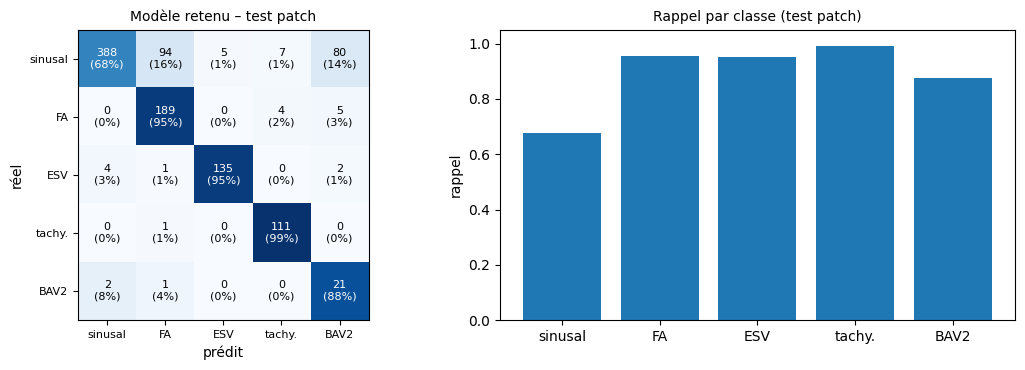

,Mesure,Test,Cible finale,Écart
0,"F1 macro, patch (test, 42 patients)",0.761,0.85,-0.089
1,"F1 macro, Holter (test, 60 patients)",0.988,0.97,0.018


In [18]:
seed_f = SEEDS_H[0]
m_final = fabrique(MODE, HOLTER, LAM_FT)(S18, y18, FC18_Z, seed_f)
p_test = proba_rythme(m_final, SB["test"]); yt = yB["test"]; r_t = evaluer_rythme(yt, p_test)
m_hol, _ = H[((HOLTER or "base"), seed_f)]; r_hol = evaluer_rythme(yA["test"], proba_rythme(m_hol, SA["test"]))
m_final.save(MODELES + "modele_patch_final.keras")
pat_t = B["patient_test"]; up = np.unique(pat_t); rb = np.random.default_rng(0); pr_t = p_test.argmax(1); bs = []
ind = {p: np.where(pat_t == p)[0] for p in up}
for _ in range(1000):
    ii = np.concatenate([ind[p] for p in rb.choice(up, len(up), replace=True)]); bs.append(f1_score(yt[ii], pr_t[ii], average="macro", labels=range(5), zero_division=0))
ic = np.percentile(bs, [2.5, 97.5])
cible = pd.DataFrame({"Mesure": ["F1 macro, patch (test, 42 patients)", "F1 macro, Holter (test, 60 patients)"], "Test": [r_t["f1_macro"], r_hol["f1_macro"]], "Cible finale": [0.85, 0.97]}); cible["Écart"] = cible["Test"] - cible["Cible finale"]
print("Stratégie :", RETENU); print("Rappels patch (test) :", dict(zip(NOMS, r_t["rappels"])), "| exactitude", r_t["exactitude"]); print("Rappels Holter (test) :", dict(zip(NOMS, r_hol["rappels"])))
print("IC 95 %% bootstrap par patient du F1 macro patch : [%.3f ; %.3f]" % tuple(ic))
display(pd.DataFrame(confusion_matrix(yt, pr_t, labels=range(5)), index=["réel " + n for n in NOMS], columns=["préd " + n for n in NOMS]))
journaliser(3, "test", f"{RETENU} (réentraîné sur 18 patients), patch", r_t["f1_macro"], f"test utilisé une seule fois ; IC95 [{ic[0]:.3f};{ic[1]:.3f}]"); journaliser(3, "test", "CNN Holter correspondant, Holter", r_hol["f1_macro"], "test Holter utilisé une seule fois")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8)); cm = confusion_matrix(yt, pr_t, labels=range(5)); cmn = cm / cm.sum(1, keepdims=True); axs[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(5):
    for j in range(5): axs[0].text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.0%})", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > .5 else "black")
axs[0].set_xticks(range(5)); axs[0].set_xticklabels(NOMS, fontsize=8); axs[0].set_yticks(range(5)); axs[0].set_yticklabels(NOMS, fontsize=8); axs[0].set_xlabel("prédit"); axs[0].set_ylabel("réel"); axs[0].set_title("Modèle retenu – test patch", fontsize=10)
axs[1].bar(NOMS, r_t["rappels"], color="tab:blue"); axs[1].set_ylim(0, 1.05); axs[1].set_ylabel("rappel"); axs[1].set_title("Rappel par classe (test patch)", fontsize=10); plt.tight_layout(); plt.show()
cible.round(3)

**Lecture (test)** *(chiffres de l'exécution ; test utilisé une seule fois)*.
- **Patch : F1 macro 0,761** (IC à 95 % par bootstrap sur les patients : **0,686 à 0,817**) contre une cible de 0,85 : écart de −0,089, et la cible est **au-dessus de l'intervalle**. **Holter : F1 macro 0,988** (cible 0,97, **atteinte**, +0,018) avec le CNN multitâche entraîné sur le Holter, une seule graine.
- **Rappels patch** : sinusal 0,68 ; FA 0,96 ; ESV 0,95 ; tachycardie 0,99 ; BAV2 0,88 (sur seulement 24 fenêtres).
- **L'erreur dominante est la fausse alerte sur le rythme sinusal** : 186 des 574 fenêtres sinusales (32 %) déclenchent une alerte (94 classées FA, 80 BAV2, 7 tachycardie, 5 ESV). Les précisions s'effondrent : environ 0,66 pour la FA et 0,19 pour le BAV2. Or le cahier des charges précise que trop d'alertes injustifiées rendent le service inutilisable.
- **Pourquoi 0,76 alors que la CV (0,896) et la validation (0,927) étaient meilleures ?** (1) Ces deux estimations sont optimistes : la stratégie, λ et les hyperparamètres ont été choisis dessus, sur 3 patients par pli et 6 patients de validation. (2) *Hypothèse non vérifiée* : le test contient davantage de rythme sinusal (55 % contre 40 % en entraînement), donc le même taux de fausses alertes dégrade davantage les précisions des classes rares.
- **Écart expliqué par** : un modèle adapté avec 18 patients seulement, une morphologie du patch différente (partie 2) qui reste confondue avec FA et BAV2 sur les rythmes sinusaux, et un test de 42 patients dont l'incertitude est large (intervalle de 0,13 de largeur).

## 8. Journal d'expériences (`jalon=3`)

In [19]:
J = pd.DataFrame(JOURNAL); J.to_csv("journal_jalon3.csv", index=False); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 200); J

,jalon,essai,config,f1_macro,remarque
0,3,Holter,cnn1d de départ (graine 0),0.9741,F1 patch val 0.7251 ; époques 9
1,3,Holter,cnn1d de départ (graine 1),0.9876,F1 patch val 0.6944 ; époques 12
2,3,grille,extraction lr=0.001 ep=40 (graine 0),0.7620,"réglage CV, une graine"
3,3,grille,extraction lr=0.01 ep=40 (graine 0),0.7927,"réglage CV, une graine"
4,3,grille,ft_complet lr=0.001 ep=20 (graine 0),0.8538,"réglage CV, une graine"
5,3,grille,ft_complet lr=0.0003 ep=20 (graine 0),0.8418,"réglage CV, une graine"
6,3,grille,ft_complet lr=0.0001 ep=20 (graine 0),0.8277,"réglage CV, une graine"
7,3,grille,ft_partiel lr=0.001 ep=20 (graine 0),0.8282,"réglage CV, une graine"
8,3,grille,ft_partiel lr=0.0003 ep=20 (graine 0),0.8163,"réglage CV, une graine"
9,3,grille,scratch lr=0.001 ep=30 (graine 0),0.3925,"réglage CV, une graine"


## 9. Page de décisions

In [20]:
def f(x, n=3): return f"{x:.{n}f}".replace(".", ",")
display(Markdown("### Tableau 1 – Toutes les stratégies (patch, validation croisée par patient, 12 patients)")); display(tableau(list(RES)))
display(Markdown("### Tableau 2 – Liste restreinte confirmée sur la validation (6 patients)")); display(T_VAL)
display(Markdown("### Tableau 3 – Modèle retenu : test (utilisé une seule fois) et écart aux cibles")); display(cible.round(3))
display(Markdown("### Tableau 4 – Étude de λ (multitâche)")); display(T_LAM)
display(Markdown("### Tableau 5 – Ablation de l'augmentation (Holter tel quel, 18 patients du patch)")); display(T_ABL)
display(Markdown(f"""
### Vérifications théoriques (réponses)
- **Normalisation par fenêtre** : pour $x' = a x + b$ avec $a>0$, $\\mu' = a\\mu + b$ et $\\sigma' = a\\sigma$, donc $z' = z$ : insensibilité au gain et au décalage constants (vérifiée numériquement, écarts de l'ordre de 1e-6 ; une inversion de polarité $a<0$ donne $-z$). Reste différent : le bruit (d'amplitude absolue fixe, donc le rapport signal/bruit après gain), la dérive et le spectre, la raie secteur, la morphologie des complexes, la fréquence cardiaque.
- **Paramètres** : CNN de départ **{m_test.count_params():,}** paramètres ; en **extraction** (tout gelé sauf la sortie) **325** entraînables ; en **ajustement fin complet** **{m_test.count_params():,}** (calcul couche par couche dans la section 1.2, vérifié par le code).

### Stratégie retenue : **{RETENU}**
*(justification détaillée ci-dessous, à lire avec les tableaux)*
""".replace(",", " ")))

### Tableau 1 – Toutes les stratégies (patch, validation croisée par patient, 12 patients)

,F1_macro_CV,écart_type_graines,écart_type_plis,R_sinusal,R_FA,R_ESV,R_tachy.,R_BAV2,durée_s
stratégie,,,,,,,,,
Holter tel quel,0.584,0.018,0.165,0.42,0.47,1.00,0.40,0.97,2
Patch seul (depuis zéro),0.485,0.014,0.118,0.49,0.44,0.76,0.66,0.07,164
Extraction de caractéristiques,0.784,0.008,0.132,0.70,0.80,0.84,0.86,0.85,54
Ajustement fin partiel,0.827,0.001,0.118,0.84,0.86,0.87,0.86,0.73,36
Ajustement fin complet,0.867,0.013,0.124,0.87,0.91,0.90,0.86,0.77,64
"Holter augmenté, tel quel",0.828,0.003,0.146,0.71,0.91,0.99,0.72,0.92,3
Holter augmenté + ajustement fin,0.877,0.009,0.087,0.89,0.93,0.98,0.86,0.69,64
"Multitâche λ=0.1, tel quel",0.577,0.012,0.165,0.42,0.49,1.00,0.34,0.96,2
Multitâche λ=0.1 + ajustement fin,0.877,0.015,0.140,0.87,0.93,0.91,0.88,0.78,67


### Tableau 2 – Liste restreinte confirmée sur la validation (6 patients)

,F1_CV,F1_validation_6_patients,écart_type_graines
stratégie,,,
Multitâche λ=0.5 + ajustement fin,0.896,0.927,0.008
Aug + multitâche + ajustement fin,0.893,0.909,0.003


### Tableau 3 – Modèle retenu : test (utilisé une seule fois) et écart aux cibles

,Mesure,Test,Cible finale,Écart
0,"F1 macro, patch (test, 42 patients)",0.761,0.85,-0.089
1,"F1 macro, Holter (test, 60 patients)",0.988,0.97,0.018


### Tableau 4 – Étude de λ (multitâche)

,F1_Holter_val,MAE_fc_Holter_bpm,MAE_fc_patch_bpm,F1_patch_18_tel_quel,F1_CV_tel_quel,F1_CV_ajust_fin,ecart_type
lam,,,,,,,
0.0,0.981,NaN,NaN,0.631,0.584,0.867,0.013
0.1,0.986,3.76,10.48,0.635,0.577,0.877,0.015
0.5,0.989,2.49,9.81,0.701,0.652,0.896,0.019
2.0,0.972,2.28,9.90,0.544,0.492,0.869,0.017


### Tableau 5 – Ablation de l'augmentation (Holter tel quel, 18 patients du patch)

,F1_patch_18_patients,F1_Holter_val
augmentation,,
aucune (référence),0.620,0.9741
gain seul,0.534,0.9821
dérive seule,0.700,0.9829
bruit seul,0.617,0.9863
secteur seul,0.642,0.9689
toutes,0.868,0.9852



### Vérifications théoriques (réponses)
- **Normalisation par fenêtre** : pour $x' = a x + b$ avec $a>0$  $\mu' = a\mu + b$ et $\sigma' = a\sigma$  donc $z' = z$ : insensibilité au gain et au décalage constants (vérifiée numériquement  écarts de l'ordre de 1e-6 ; une inversion de polarité $a<0$ donne $-z$). Reste différent : le bruit (d'amplitude absolue fixe  donc le rapport signal/bruit après gain)  la dérive et le spectre  la raie secteur  la morphologie des complexes  la fréquence cardiaque.
- **Paramètres** : CNN de départ **51 365** paramètres ; en **extraction** (tout gelé sauf la sortie) **325** entraînables ; en **ajustement fin complet** **51 365** (calcul couche par couche dans la section 1.2  vérifié par le code).

### Stratégie retenue : **Multitâche λ=0.5 + ajustement fin**
*(justification détaillée ci-dessous  à lire avec les tableaux)*


### Décisions

**1. Stratégie retenue pour un troisième modèle de patch.** Pré-entraîner sur le Holter un **CNN multitâche** (rythme + fréquence cardiaque, **λ = 0,5**), puis réaliser un **ajustement fin complet** (Adam 1e-3, 20 époques, poids de classes recalculés) sur les patients annotés du patch.
- *Pourquoi* : meilleur F1 en validation croisée (0,896 ± 0,019) et en validation (0,927), contre 0,867 pour l'ajustement fin sans tâche auxiliaire et 0,485 pour un CNN entraîné sur le patch seul. L'écart avec l'ajustement fin simple (+0,029) est **suggéré, pas démontré** (2 graines) ; la stratégie reste raisonnable car elle ne coûte pas plus cher à entraîner.
- *Si aucun patient du patch n'est annoté* : entraîner sur le Holter **augmenté** (gain, dérive, bruit, secteur) donne 0,828 en CV, contre 0,584 sans augmentation (+0,24), et ne dégrade pas le Holter. C'est la solution de repli la moins chère.
- *Ce qui n'est pas retenu* : le CNN sur le patch seul (insuffisant avec 12 patients) ; l'augmentation en plus de l'ajustement fin (+0,010, dans le bruit).

**2. Combien de patients faire annoter en priorité : 6 à 9, choisis pour couvrir les cinq rythmes.**
- La courbe d'apprentissage monte de 0,78 (3 patients) à 0,92 (6 patients) puis reste à 0,91–0,92 jusqu'à 12 ; le patch seul en reste loin (0,52 à 12 patients).
- Avec 3 patients, le résultat dépend de leurs rythmes (écart-type 0,14) : **chaque patient étant dominé par un ou deux rythmes, il faut viser au moins 2 à 3 patients par rythme rare** (BAV2, ESV, FA), plutôt qu'un nombre arbitraire.
- *Limite* : 3 tirages et 6 patients de validation ne permettent pas de dire si 12 patients feraient mieux que 6 ; au-delà de 9, le gain n'est pas visible ici.
- *Priorité aussi* : de **nouveaux patients sinusaux**, car les fausses alertes sur le rythme sinusal sont la principale erreur du test (32 % des fenêtres sinusales).

**3. Écart aux cibles** (le jalon n'exige pas les cibles finales) : patch **0,761** contre 0,85 (−0,089, IC à 95 % 0,686–0,817) ; Holter **0,988** contre 0,97 (atteinte). L'écart patch vient des fausses alertes sur le rythme sinusal (partie 7), de la morphologie propre au patch que les transformations ne simulent pas, et du faible nombre de patients annotés. Pistes pour la suite (non testées) : seuil d'alerte par classe pour limiter les fausses alertes, plus de patients annotés, filtre passe-haut en prétraitement.

**4. Réponses aux vérifications théoriques.** Normalisation par fenêtre : $z' = z$ pour $x' = a x + b$, $a>0$ (vérifié numériquement) ; restent différents le bruit absolu (donc le rapport signal/bruit), la dérive et le spectre, la morphologie, la fréquence cardiaque. Paramètres : **51 365** en ajustement fin complet, **325** en extraction de caractéristiques.

**5. Limites et reproductibilité.**
- 2 graines par configuration (écart-type entre graines grossier) ; CV sur 12 patients à 3 patients par pli ; validation de 6 patients dont 6 fenêtres de FA.
- Hyperparamètres d'adaptation, λ et stratégie choisis sur la CV / validation : ces estimations sont un peu optimistes, le test non.
- Le test du patch comporte seulement 24 fenêtres de BAV2 : ce rappel est très incertain.
- `uc3_demarrage.ipynb` n'était pas disponible : `A`, `B`, `poids`, `evaluer_rythme`, `journaliser` sont réimplémentés.
- Calcul : CPU uniquement, environ 2 minutes par CNN Holter ; modèles sauvegardés dans `modeles_jalon3/` ; journal d'expériences dans `journal_jalon3.csv`.
- Usage d'un assistant IA (Claude, Anthropic) pour produire ce notebook : à déclarer et à relire par le groupe.

## Reproductibilité

- **Environnement de notre exécution** (affiché en début de notebook) : Python 3.12.3, numpy 2.4.4, scipy 1.17.1, scikit-learn 1.8.0, TensorFlow 2.21.0, Keras 3.15.1.
- **Graines** : nous avons utilisé 42 pour le modèle final et les graines 0 et 1 pour les comparaisons (2 graines par configuration).
- **Données** : `uc3_holterA.npz` et `uc3_patchB.npz` ; découpage par patient (Holter 280/60/60, patch 12/6/42) vérifié par des assertions ; validation croisée par patient (`GroupKFold`, 4 plis) sur les 12 patients d'entraînement du patch.
- **Matériel de calcul et temps** : nous avons exécuté le notebook sur CPU uniquement (1 cœur), en environ 2 minutes par CNN Holter ; nous avons désactivé le mode rapide (`UC3_RAPIDE=1`).
- **Procédure** : installer les dépendances du README, placer les fichiers `.npz`, puis exécuter le notebook du début à la fin ; nos modèles Holter sont sauvegardés dans `modeles_jalon3/` et le journal d'expériences se reconstruit à chaque exécution.
- Nous avons exporté après coup les modèles de la démonstration Streamlit (`artifacts/`) avec Python 3.13, TensorFlow 2.21.0 et Keras 3.13.2 (voir `artifacts/jalon3/config.json`) ; les chiffres de ce notebook sont ceux de notre exécution, ceux de l'application proviennent de ces exports et peuvent différer légèrement. Dans l'application, nous réentraînons les stratégies comparables sur les 18 patients annotés du patch (voir le README).